
# Intelligent Predictive Maintenance & Machine Failure Risk Management

## 1. Problem Understanding

### Business Problem
Unexpected machine failures cause production delays, increased maintenance costs, and operational disruptions. Fixed maintenance schedules may result in unnecessary servicing or missed failures.

### Objective
Predict machine failure risk using operational sensor data to support maintenance planning and inspection prioritization.

### Prediction Task
- Problem Type: Binary Classification
- Target: Machine failure
- 0: No Failure
- 1: Failure

### Project Approach
1. Understand, audit, and prepare the dataset.
2. Explore sensor patterns and class imbalance.
3. Develop Logistic Regression, Random Forest, and ANN models.
4. Evaluate model reliability and prediction errors.
5. Conduct a controlled ANN experiment.
6. Recommend a suitable model and maintenance strategy.

### Expected Outcome
A reliable and reproducible machine failure risk prediction solution that supports evidence-based maintenance decisions.




## 2. CBIM Canvas — Predictive Maintenance

| Component | Description |
|---|---|
| Business Problem | Unexpected machine failures disrupt production and increase maintenance costs. |
| Stakeholders | Maintenance team, production managers, and manufacturing management. |
| Business Objective | Reduce unexpected failures and improve maintenance prioritization. |
| Current Process | Fixed preventive maintenance schedules. |
| Proposed Solution | Predict machine failure risk using ML and ANN models. |
| Data Available | Product type, temperatures, rotational speed, torque, and tool wear. |
| AI Task | Binary classification (0 = No Failure, 1 = Failure). |
| Success Metrics | Recall, Precision, F1, ROC-AUC, PR-AUC, and error costs. |
| Business Decision | Prioritize inspections based on predicted failure risk. |
| Key Risks | Missed failures, false alarms, class imbalance, and data leakage. |
| Constraints | Synthetic dataset, no true machine-level time series, and unknown real maintenance costs. |
| Expected Value | Better maintenance decisions and potentially reduced downtime and unnecessary inspections. |

### Key Business Priority
Identify as many actual failures as practical while controlling unnecessary inspections and their costs.

### Assumption
Actual maintenance costs are unavailable. Any cost-based analysis will use clearly labeled hypothetical values.



## 3. Dataset Loading and Initial Inspection

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI)

The dataset contains machine operating measurements and failure information.

**Objective:**
- Load the dataset.
- Check the number of rows and columns.
- Display the first five records.
- Identify available features and the target column.

No preprocessing or cleaning is performed at this stage.


In [1]:

import pandas as pd

df = pd.read_csv("ai4i2020.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



## 4. Dataset Structure and Data Types

We examine the dataset to understand:
- Data types of each column.
- Missing values.
- Number of unique values.
- Basic dataset information.

This helps identify potential data-quality issues before preprocessing.


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nUnique Values:")
display(df.nunique().to_frame("Unique Count"))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,Missing Count
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Unique Values:


,Unique Count
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2



# Phase 1 — Business Understanding, Data Audit and Preparation

In this phase, we understand the business problem, inspect dataset quality, explore machine operating patterns, and prepare the data for modeling.

**Main activities:**
- Business understanding and CBIM Canvas
- Dataset inspection and data-quality checks
- Exploratory Data Analysis (EDA)
- Class imbalance and sensor relationship analysis
- Leakage-free preprocessing



### 5. Duplicate and Category Validation

We check for duplicate records and verify whether product types and target labels contain valid values.


In [3]:

print("Duplicate Rows:", df.duplicated().sum())

print("\nProduct Type Distribution:")
print(df["Type"].value_counts(dropna=False))

print("\nTarget Values:")
print(df["Machine failure"].value_counts(dropna=False))

print("\nInvalid Product Types:",
      (~df["Type"].isin(["L", "M", "H"])).sum())

print("Invalid Target Values:",
      (~df["Machine failure"].isin([0, 1])).sum())


Duplicate Rows: 0

Product Type Distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Target Values:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Invalid Product Types: 0
Invalid Target Values: 0



**Findings:**
- No duplicate records or invalid categories were found.
- Product types: L (60%), M (29.97%), H (10.03%).
- Failures represent only 3.39% of records.
- The target is highly imbalanced, so accuracy alone is insufficient.
- Class imbalance must be considered during model training and evaluation.



### 6. Sensor Validity and Descriptive Statistics

We examine sensor ranges, summary statistics, and invalid readings to identify possible data-quality issues before cleaning.


In [4]:

sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

display(df[sensor_cols].describe().T.round(2))

print("\nNon-finite values:")
print((~np.isfinite(df[sensor_cols])).sum() if "np" in globals()
      else "NumPy not imported yet")

print("\nNon-positive readings:")
for col in sensor_cols:
    print(f"{col}: {(df[col] <= 0).sum()}")

print("\nProcess Temperature Below Air Temperature:",
      (df["Process temperature [K]"] < df["Air temperature [K]"]).sum())


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0



Non-finite values:
NumPy not imported yet

Non-positive readings:
Air temperature [K]: 0
Process temperature [K]: 0
Rotational speed [rpm]: 0
Torque [Nm]: 0
Tool wear [min]: 120

Process Temperature Below Air Temperature: 0



**Findings:**
- Sensor values are within plausible preliminary ranges.
- No non-positive temperature, speed, or torque readings were found.
- Tool wear has 120 zero values, which may be valid.
- Process temperature is always above air temperature.
- Extreme sensor readings require further investigation before cleaning.



### 7. Non-Finite Values and Outlier Detection

We check for infinite sensor values and identify potential outliers using the IQR method.

Outliers will be investigated before deciding whether treatment is necessary.


In [5]:

import numpy as np

print("Non-finite values:")
print((~np.isfinite(df[sensor_cols])).sum())

outliers = []

for col in sensor_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outliers.append({
        "Sensor": col,
        "Outliers": count,
        "Percentage": round(count / len(df) * 100, 2)
    })

display(pd.DataFrame(outliers))


Non-finite values:
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


,Sensor,Outliers,Percentage
0,Air temperature [K],0,0.00
1,Process temperature [K],0,0.00
2,Rotational speed [rpm],418,4.18
3,Torque [Nm],69,0.69
4,Tool wear [min],0,0.00



**Findings:**
- No infinite or missing sensor values were found.
- Rotational speed has 418 outliers (4.18%).
- Torque has 69 outliers (0.69%).
- Other sensors have no IQR outliers.
- Outliers are retained for now because extreme conditions may indicate machine failure.



### 8. Outlier Impact on Machine Failure

We compare failure rates for normal and outlier sensor readings to understand whether extreme operating conditions are associated with machine failures.


In [6]:

for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)

    result = df.groupby(outlier)["Machine failure"].agg(
        Records="count",
        Failures="sum",
        Failure_Rate="mean"
    )

    result.index = result.index.map({False: "Normal", True: "Outlier"})
    result["Failure_Rate"] = (result["Failure_Rate"] * 100).round(2)

    print(f"\n{col}")
    display(result)



Rotational speed [rpm]


,Records,Failures,Failure_Rate
Rotational speed [rpm],,,
Normal,9582,304,3.17
Outlier,418,35,8.37



Torque [Nm]


,Records,Failures,Failure_Rate
Torque [Nm],,,
Normal,9931,277,2.79
Outlier,69,62,89.86



**Findings:**
- Rotational speed outliers have an 8.37% failure rate, compared with 3.17% for normal readings.
- Torque outliers have an 89.86% failure rate, compared with 2.79% for normal readings.
- Extreme sensor readings show strong associations with machine failure.
- We retain these observations because removing them could discard valuable failure patterns.
- These are associations, not proof of causation.



### 9. Sensor Distribution Analysis

We use histograms and boxplots to understand sensor distributions, variability, skewness, and extreme operating readings.


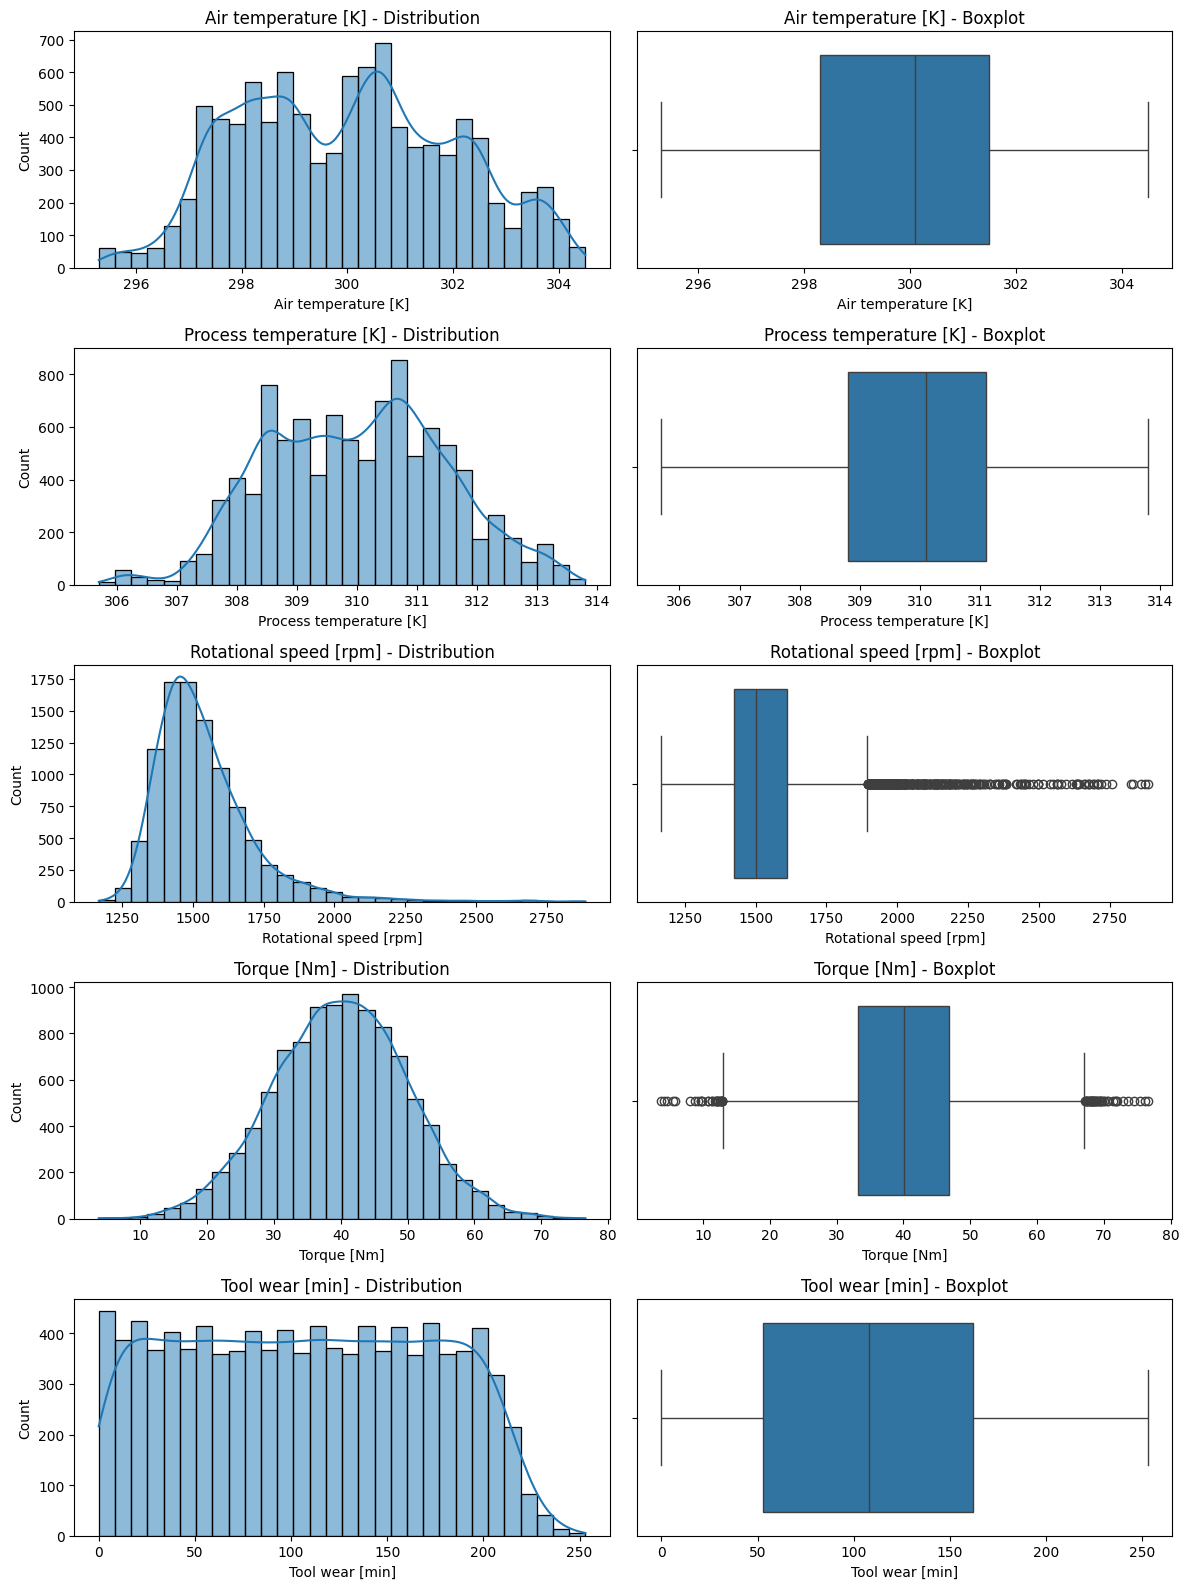

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for i, col in enumerate(sensor_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} - Distribution")

    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} - Boxplot")

plt.tight_layout()
plt.show()



**Findings:**
- Air and process temperatures show multiple peaks without IQR outliers.
- Rotational speed is right-skewed with several high-value outliers.
- Torque is approximately bell-shaped with outliers at both ends.
- Tool wear is broadly distributed without IQR outliers.
- Extreme sensor readings are retained for failure prediction.



### 10. Sensor Patterns by Machine Failure

We compare sensor measurements between failed and non-failed records to identify operating conditions associated with machine failure.


,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


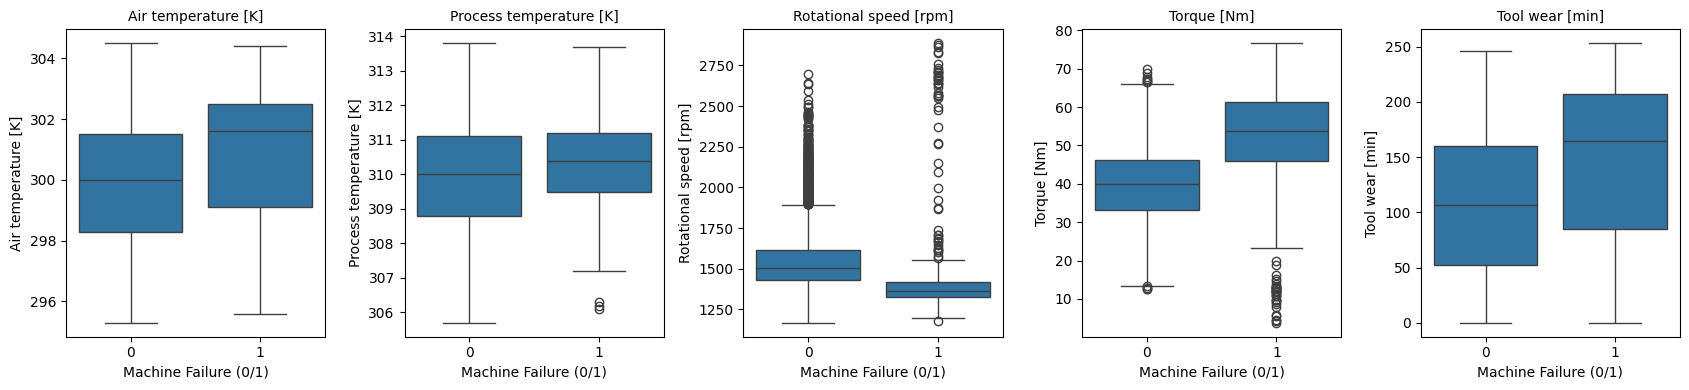

In [8]:

failure_summary = df.groupby("Machine failure")[sensor_cols].mean().T
failure_summary.columns = ["No Failure", "Failure"]

display(failure_summary.round(2))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for i, col in enumerate(sensor_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Machine Failure (0/1)")

plt.tight_layout()
plt.show()



**Findings:**
- Failed records have higher average torque (50.17 vs 39.63 Nm).
- Tool wear is higher during failures (143.78 vs 106.69 min).
- Air temperature is slightly higher in failed records.
- Rotational speed is lower on average during failures, but extreme high speeds also occur.
- Process temperature shows a smaller average difference.
- These patterns suggest associations, not causation.



### 11. Sensor Correlation Analysis

We calculate correlations between numerical sensors and machine failure to identify linear relationships and highly related features.


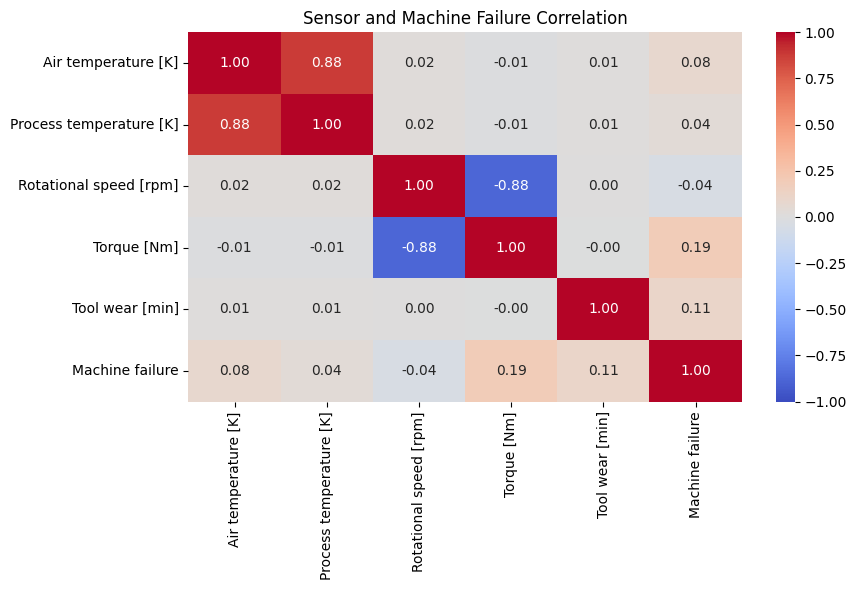

In [9]:

corr_cols = sensor_cols + ["Machine failure"]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)

plt.title("Sensor and Machine Failure Correlation")
plt.tight_layout()
plt.show()



**Findings:**
- Air and process temperatures show strong positive correlation (+0.88).
- Rotational speed and torque show strong negative correlation (-0.88).
- Torque (+0.19) and tool wear (+0.11) have the highest positive linear correlations with failure.
- Individual sensor correlations with failure are relatively weak.
- All five sensors are retained initially because nonlinear interactions may provide useful information.



### 12. Product Type and Machine Failure

We compare failure rates across product types (L, M, H) to identify possible associations between product quality category and machine failure.


,Records,Failures,Failure_Rate
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


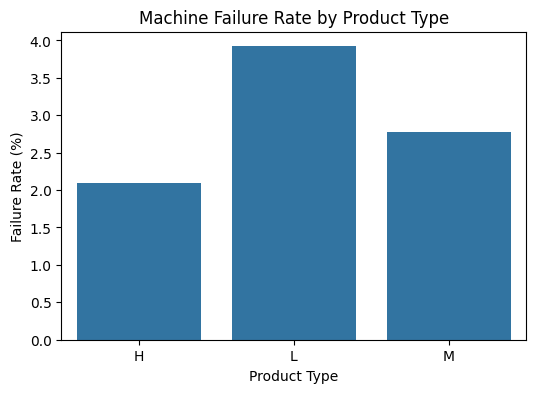

In [10]:

type_summary = df.groupby("Type")["Machine failure"].agg(
    Records="count",
    Failures="sum",
    Failure_Rate="mean"
)

type_summary["Failure_Rate"] = (
    type_summary["Failure_Rate"] * 100
).round(2)

display(type_summary)

plt.figure(figsize=(6, 4))
sns.barplot(x=type_summary.index,
            y=type_summary["Failure_Rate"])

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.show()



**Findings:**
- Type L has the highest failure rate (3.92%).
- Type M has a failure rate of 2.77%.
- Type H has the lowest failure rate (2.09%).
- Product type shows an association with machine failure.
- We retain Type as a categorical feature for modeling.



### 13. Sensor Interaction Analysis

We examine how rotational speed, torque, and temperature difference relate to machine failure.

This helps identify possible nonlinear patterns and useful features for modeling.


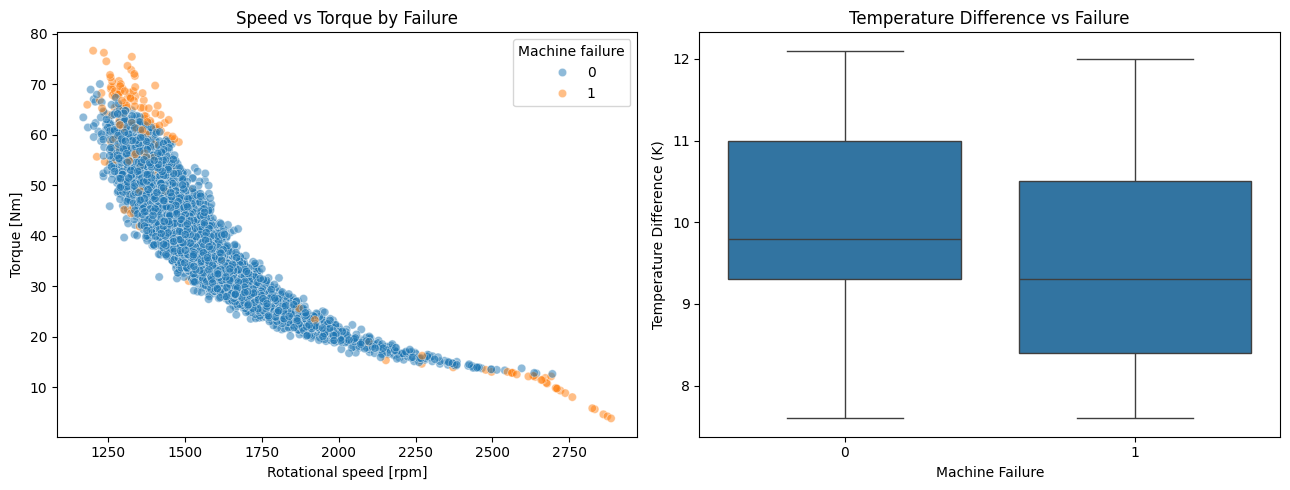

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df, x="Rotational speed [rpm]", y="Torque [Nm]",
    hue="Machine failure", alpha=0.5, ax=axes[0]
)
axes[0].set_title("Speed vs Torque by Failure")

temp_difference = df["Process temperature [K]"] - df["Air temperature [K]"]

sns.boxplot(x=df["Machine failure"], y=temp_difference, ax=axes[1])
axes[1].set_title("Temperature Difference vs Failure")
axes[1].set_ylabel("Temperature Difference (K)")
axes[1].set_xlabel("Machine Failure")

plt.tight_layout()
plt.show()



**Findings:**
- Rotational speed and torque show a strong inverse relationship.
- Failures appear more frequently at extreme speed-torque combinations.
- Failed records generally show a lower temperature difference.
- Temperature difference may provide useful additional information.
- These patterns are associations, not proof of causation.



### 14. Feature Engineering Investigation

We explore temperature difference and a speed-torque interaction feature to capture operating patterns that individual sensors may not fully represent.


In [12]:

feature_analysis = pd.DataFrame({
    "Temperature_Difference": (
        df["Process temperature [K]"] - df["Air temperature [K]"]
    ),
    "Speed_Torque_Product": (
        df["Rotational speed [rpm]"] * df["Torque [Nm]"]
    ),
    "Machine failure": df["Machine failure"]
})

display(
    feature_analysis.groupby("Machine failure").agg(
        ["mean", "median", "std"]
    ).round(2)
)

print("\nCorrelation with Machine Failure:")
display(
    feature_analysis.corr()["Machine failure"].round(3)
)


Temperature_Difference              Speed_Torque_Product  \
                                  mean median   std                 mean   
Machine failure                                                            
0                                10.02    9.8  0.99             59631.04   
1                                 9.40    9.3  1.16             69545.80   

                                    
                  median       std  
Machine failure                     
0                59616.7   9658.11  
1                72683.8  17677.07


Correlation with Machine Failure:


Temperature_Difference   -0.112
Speed_Torque_Product      0.176
Machine failure           1.000
Name: Machine failure, dtype: float64


**Findings:**
- Failed records have a lower average temperature difference (9.40 K vs 10.02 K).
- Failed records have a higher speed-torque product (69,545.80 vs 59,631.04).
- Both features show associations with machine failure.
- We will evaluate these candidate features during model development.
- No features are removed based on correlation alone.



### 15. Feature Selection and Leakage Prevention

We separate valid input features, the prediction target, identifiers, and prohibited failure indicators.

Failure-mode columns and identifiers are excluded to prevent leakage and ensure meaningful model evaluation.


In [13]:

target_col = "Machine failure"

excluded_cols = [
    "UDI", "Product ID",
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Selected Features:", feature_cols)
print("Excluded Columns:", excluded_cols)
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

assert not set(excluded_cols).intersection(X.columns)
assert target_col not in X.columns

print("\nLeakage Safeguard: Passed")


Selected Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Excluded Columns: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Feature Shape: (10000, 6)
Target Shape: (10000,)

Leakage Safeguard: Passed



### 16. Train, Validation and Test Split

We divide the dataset into 70% training, 15% validation, and 15% testing.

- Training: Learn patterns from data.
- Validation: Tune models and select thresholds.
- Testing: Evaluate the final selected model.

Stratification preserves the rare failure class, and random_state=42 supports reproducibility.


In [14]:

from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    stratify=y_temp, random_state=SEED
)

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"{name}: {len(target)} records")
    print(f"  Failures: {target.sum()}")
    print(f"  Failure Rate: {target.mean():.2%}")

print("\nOverlapping row indices:")
print("Train/Validation:", len(set(X_train.index) & set(X_val.index)))
print("Train/Test:", len(set(X_train.index) & set(X_test.index)))
print("Validation/Test:", len(set(X_val.index) & set(X_test.index)))


Train: 7000 records
  Failures: 237
  Failure Rate: 3.39%
Validation: 1500 records
  Failures: 51
  Failure Rate: 3.40%
Test: 1500 records
  Failures: 51
  Failure Rate: 3.40%

Overlapping row indices:
Train/Validation: 0
Train/Test: 0
Validation/Test: 0



**Findings:**
- Training: 7,000 records with 237 failures.
- Validation: 1,500 records with 51 failures.
- Testing: 1,500 records with 51 failures.
- Failure rates remain approximately 3.4% across all splits.
- No overlapping records were found.
- The test set will remain untouched during model selection and tuning.



### 17. Leakage-Free Preprocessing

We prepare numerical and categorical features for modeling.

- StandardScaler scales numerical features for Logistic Regression and ANN.
- OneHotEncoder converts product types into numerical columns.
- Random Forest uses encoded categories without scaling.
- Preprocessing is fitted only on training data to prevent leakage.


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = sensor_cols
categorical_features = ["Type"]

preprocessor_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False), categorical_features)
])

preprocessor_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False), categorical_features)
])

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_val_scaled = preprocessor_scaled.transform(X_val)

X_train_tree = preprocessor_tree.fit_transform(X_train)
X_val_tree = preprocessor_tree.transform(X_val)

print("Scaled Train:", X_train_scaled.shape)
print("Scaled Validation:", X_val_scaled.shape)
print("Tree Train:", X_train_tree.shape)
print("Tree Validation:", X_val_tree.shape)

print("\nScaled Feature Names:")
print(preprocessor_scaled.get_feature_names_out())


Scaled Train: (7000, 8)
Scaled Validation: (1500, 8)
Tree Train: (7000, 8)
Tree Validation: (1500, 8)

Scaled Feature Names:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']



**Findings:**
- Both preprocessing pipelines produce 8 input columns.
- Five numerical features are retained.
- Product Type is converted into three one-hot encoded columns.
- Scaling is applied for Logistic Regression and ANN.
- Random Forest uses unscaled numerical features.
- Preprocessing was fitted only on training data.



### 18. Preprocessing Verification

We verify that numerical features are standardized and product types are correctly encoded before training models.


In [16]:

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=preprocessor_scaled.get_feature_names_out()
)

print("Numerical Feature Means:")
print(scaled_df.iloc[:, :5].mean().round(3))

print("\nNumerical Feature Standard Deviations:")
print(scaled_df.iloc[:, :5].std(ddof=0).round(3))

print("\nOne-Hot Encoding Check:")
print(scaled_df.iloc[:, 5:].sum(axis=1).value_counts())

print("\nMissing Values After Preprocessing:",
      scaled_df.isna().sum().sum())


Numerical Feature Means:
num__Air temperature [K]        0.0
num__Process temperature [K]    0.0
num__Rotational speed [rpm]    -0.0
num__Torque [Nm]                0.0
num__Tool wear [min]            0.0
dtype: float64

Numerical Feature Standard Deviations:
num__Air temperature [K]        1.0
num__Process temperature [K]    1.0
num__Rotational speed [rpm]     1.0
num__Torque [Nm]                1.0
num__Tool wear [min]            1.0
dtype: float64

One-Hot Encoding Check:
1.0    7000
Name: count, dtype: int64

Missing Values After Preprocessing: 0



## Phase 1 Summary — Data Audit, EDA and Preparation

### Dataset Quality
- Dataset: 10,000 records and 14 columns.
- No missing values, duplicates, invalid categories, or non-finite sensor readings.
- No cleaning or row removal was required.
- Zero tool wear readings were retained as potentially valid.

### Class Imbalance
- No Failure: 9,661 records (96.61%).
- Failure: 339 records (3.39%).
- Recall, Precision, F1, and PR-AUC will be important evaluation metrics.

### Important EDA Findings
- Torque outliers: 69 records; 89.86% failure rate.
- Rotational speed outliers: 418 records; 8.37% failure rate.
- Failed records have higher average torque and tool wear.
- Air and process temperatures are strongly correlated (+0.88).
- Rotational speed and torque are strongly negatively correlated (-0.88).
- Product Type L has the highest observed failure rate (3.92%).

### Feature Engineering
- Investigated temperature difference and speed-torque product.
- Both showed associations with failure.
- Their predictive benefit requires validation-based testing.

### Data Preparation
- Selected 5 numerical features and 1 categorical feature.
- Excluded UDI, Product ID, and all five failure-mode indicators.
- Used stratified 70/15/15 train, validation, and test splits.
- Applied training-only StandardScaler and OneHotEncoder.
- Final preprocessed input: 8 columns.
- Preprocessing checks passed without missing values.

### Decisions and Limitations
- Retain sensor outliers because they may contain failure-related information.
- Use class imbalance handling during model training.
- Keep the test set reserved for final evaluation.
- The dataset is synthetic and not a true machine-level time series.
- Observed sensor relationships do not establish causation.



# Phase 2 — ML and ANN Development

## 20. Logistic Regression Baseline

Logistic Regression is our first model for predicting machine failure.

- Uses standardized numerical features and encoded product types.
- Applies balanced class weights to address rare failures.
- Provides a simple baseline for comparison with Random Forest and ANN.
- Uses the validation set for initial performance evaluation.


In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED
)

lr_model.fit(X_train_scaled, y_train)

lr_val_prob = lr_model.predict_proba(X_val_scaled)[:, 1]
lr_val_pred = (lr_val_prob >= 0.5).astype(int)

print("Logistic Regression - Validation Results")
print("Precision:", round(precision_score(y_val, lr_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, lr_val_pred), 4))
print("F1-score:", round(f1_score(y_val, lr_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, lr_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, lr_val_prob), 4))


Logistic Regression - Validation Results
Precision: 0.1365
Recall: 0.7255
F1-score: 0.2298
ROC-AUC: 0.875
PR-AUC: 0.3829



**Findings:**
- Logistic Regression achieved 72.55% recall and 13.65% precision.
- F1-score is 0.2298, ROC-AUC is 0.8750, and PR-AUC is 0.3829.
- The model detects many failures but produces numerous false alarms.
- Further model comparisons and threshold analysis are required.



## 21. Random Forest Classifier

Random Forest combines multiple decision trees to predict machine failure.

- Captures nonlinear sensor relationships.
- Uses class weights to address failure imbalance.
- Uses the same train and validation split as Logistic Regression.
- Provides an ensemble model for comparison.


In [18]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X_train_tree, y_train)

rf_val_prob = rf_model.predict_proba(X_val_tree)[:, 1]
rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("Random Forest - Validation Results")
print("Precision:", round(precision_score(y_val, rf_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_val_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, rf_val_prob), 4))


Random Forest - Validation Results
Precision: 0.7857
Recall: 0.4314
F1-score: 0.557
ROC-AUC: 0.9687
PR-AUC: 0.6647



**Findings:**
- Random Forest achieved 78.57% precision and 43.14% recall.
- F1-score is 0.5570, ROC-AUC is 0.9687, and PR-AUC is 0.6647.
- Random Forest outperformed Logistic Regression on F1, ROC-AUC, and PR-AUC.
- Logistic Regression detected more failures at the 0.5 threshold.
- Threshold tuning is required before selecting the final model.



## 22. Artificial Neural Network (ANN)

We develop an ANN to predict machine failure using the same training and validation data.

- Architecture: Dense(32) → Dense(16) → Dense(1)
- Hidden activation: ReLU
- Output activation: Sigmoid
- Optimizer: Adam (learning rate 0.001)
- Loss: Binary Crossentropy
- Batch size: 32
- Maximum epochs: 50
- Early stopping prevents unnecessary training.
- Class weights address the rare failure class.


In [19]:

import random
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes.astype(int), weights))

ann_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled.astype("float32"),
    y_train,
    validation_data=(X_val_scaled.astype("float32"), y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.5713 - pr_auc: 0.2270 - roc_auc: 0.8061 - val_loss: 0.4677 - val_pr_auc: 0.3149 - val_roc_auc: 0.8726
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4040 - pr_auc: 0.4516 - roc_auc: 0.9087 - val_loss: 0.3895 - val_pr_auc: 0.3826 - val_roc_auc: 0.9019
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3477 - pr_auc: 0.5267 - roc_auc: 0.9294 - val_loss: 0.3522 - val_pr_auc: 0.4171 - val_roc_auc: 0.9160
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3216 - pr_auc: 0.5553 - roc_auc: 0.9387 - val_loss: 0.3277 - val_pr_auc: 0.4378 - val_roc_auc: 0.9246
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3045 - pr_auc: 0.5679 - roc_auc: 0.9449 - val_loss: 0.3127 - val_pr_auc: 0.4581 - val_roc_auc: 0.9320
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2910 - pr_auc: 0.5863 - roc_auc: 0.9501 - val_loss: 0.2991 - val_pr_auc: 0.4692 - val_roc_auc: 0.9375
Epoch 7/50
219/2


## 23. ANN Validation Evaluation

We evaluate the trained ANN using the same validation data and classification metrics as the traditional ML models.

The initial threshold is 0.5. Final threshold selection will be performed later.


In [20]:

ann_val_prob = ann_model.predict(
    X_val_scaled.astype("float32"),
    verbose=0
).ravel()

ann_val_pred = (ann_val_prob >= 0.5).astype(int)

print("ANN - Validation Results")
print("Precision:", round(precision_score(y_val, ann_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, ann_val_pred), 4))
print("F1-score:", round(f1_score(y_val, ann_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, ann_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, ann_val_prob), 4))

print("\nTraining Summary:")
print("Epochs Run:", len(history.history["loss"]))
print("Best Validation Loss:", round(min(history.history["val_loss"]), 4))


ANN - Validation Results
Precision: 0.2635
Recall: 0.8627
F1-score: 0.4037
ROC-AUC: 0.9696
PR-AUC: 0.617

Training Summary:
Epochs Run: 37
Best Validation Loss: 0.2131



**Findings:**
- ANN achieved 86.27% recall, the highest among the three models.
- Random Forest achieved the highest precision (78.57%), F1 (0.5570), and PR-AUC (0.6647).
- ANN achieved the highest ROC-AUC (0.9696), only slightly above Random Forest (0.9687).
- ANN trained for 37 epochs, with a best validation loss of 0.2131.
- No final model is selected yet; threshold and reliability analysis are required.



## 24. ANN Training Curves

We compare training and validation loss, ROC-AUC, and PR-AUC across epochs to examine learning progress, convergence, and possible overfitting.


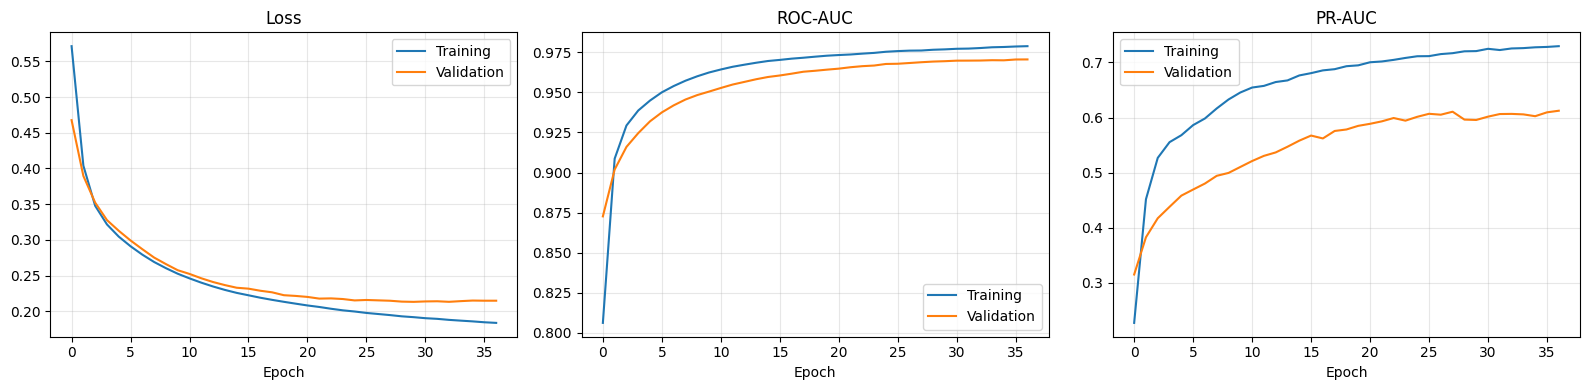

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = [
    ("loss", "Loss"),
    ("roc_auc", "ROC-AUC"),
    ("pr_auc", "PR-AUC")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.plot(history.history[metric], label="Training")
    ax.plot(history.history[f"val_{metric}"], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Findings:**
- Training and validation loss decreased during early epochs.
- Validation loss stabilized and slightly increased toward the end.
- ROC-AUC remained strong on validation data (around 0.97).
- A training-validation PR-AUC gap suggests mild overfitting.
- Early stopping restored the best weights based on validation loss.



## 25. Initial Model Comparison

We compare Logistic Regression, Random Forest, and ANN using the same validation data and a 0.5 decision threshold.

Final model selection will consider reliability, threshold sensitivity, and business costs.


In [22]:

models = {
    "Logistic Regression": lr_val_prob,
    "Random Forest": rf_val_prob,
    "ANN": ann_val_prob
}

comparison = []

for name, probabilities in models.items():
    predictions = (probabilities >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "PR_AUC": average_precision_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))


,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.1365,0.7255,0.2298,0.8750,0.3829
1,Random Forest,0.7857,0.4314,0.5570,0.9687,0.6647
2,ANN,0.2635,0.8627,0.4037,0.9696,0.6170



**Findings:**
- ANN achieved the highest recall (86.27%) and ROC-AUC (0.9696).
- Random Forest achieved the highest precision (78.57%), F1-score (0.5570), and PR-AUC (0.6647).
- No model is selected yet because threshold tuning and error-cost analysis are pending.



## 26. Random Forest Hyperparameter Tuning

We test different Random Forest settings to improve failure prediction.

- Tune tree depth, leaf size, and class weights.
- Use the validation set to compare models.
- Prioritize PR-AUC for rare failure detection.
- Keep the test set untouched.


In [23]:

from sklearn.model_selection import ParameterGrid

param_grid = {
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_tuning_results = []
best_rf = None
best_rf_score = -1

for params in ParameterGrid(param_grid):
    model = RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1,
        **params
    )

    model.fit(X_train_tree, y_train)
    prob = model.predict_proba(X_val_tree)[:, 1]

    pr_auc = average_precision_score(y_val, prob)

    rf_tuning_results.append({
        **params,
        "PR_AUC": pr_auc,
        "ROC_AUC": roc_auc_score(y_val, prob)
    })

    if pr_auc > best_rf_score:
        best_rf_score = pr_auc
        best_rf = model

rf_tuning_df = pd.DataFrame(rf_tuning_results)
display(rf_tuning_df.sort_values("PR_AUC", ascending=False).round(4))

print("Best RF Validation PR-AUC:", round(best_rf_score, 4))


,class_weight,max_depth,min_samples_leaf,PR_AUC,ROC_AUC
10,balanced_subsample,20.0,1,0.6898,0.9712
6,balanced_subsample,NaN,1,0.6895,0.9713
4,balanced,20.0,1,0.6660,0.9690
0,balanced,NaN,1,0.6647,0.9687
7,balanced_subsample,NaN,3,0.6527,0.9687
11,balanced_subsample,20.0,3,0.6527,0.9687
1,balanced,NaN,3,0.6355,0.9761
5,balanced,20.0,3,0.6353,0.9762
9,balanced_subsample,10.0,3,0.6192,0.9728
2,balanced,10.0,1,0.6164,0.9715


Best RF Validation PR-AUC: 0.6898



**Findings:**
- Tested 12 Random Forest configurations.
- Best settings: max_depth=20, min_samples_leaf=1, class_weight=balanced_subsample.
- Validation PR-AUC improved from 0.6647 to 0.6898.
- Validation ROC-AUC improved from 0.9687 to 0.9712.
- Final performance must be verified on the held-out test set.



## 27. Tuned Random Forest Evaluation

We compare the original and tuned Random Forest models using the same validation data and a 0.5 threshold.

This helps determine whether hyperparameter tuning improved failure detection and reduced false alarms.


In [26]:

from sklearn.metrics import confusion_matrix
best_rf_val_prob = best_rf.predict_proba(X_val_tree)[:, 1]
best_rf_val_pred = (best_rf_val_prob >= 0.5).astype(int)

rf_results = []

for name, prob in [
    ("Original RF", rf_val_prob),
    ("Tuned RF", best_rf_val_prob)
]:
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    rf_results.append({
        "Model": name,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR_AUC": average_precision_score(y_val, prob),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

display(pd.DataFrame(rf_results).round(4))


,Model,Precision,Recall,F1,PR_AUC,TP,FP,FN,TN
0,Original RF,0.7857,0.4314,0.5570,0.6647,22,6,29,1443
1,Tuned RF,0.8148,0.4314,0.5641,0.6898,22,5,29,1444



**Findings:**
- Tuned Random Forest improved precision from 78.57% to 81.48%.
- PR-AUC improved from 0.6647 to 0.6898.
- False positives decreased from 6 to 5.
- Recall remained unchanged at 43.14%, with 29 missed failures.
- Threshold analysis is still required to improve the balance between missed failures and false alarms.



## 28. Random Forest Threshold Sensitivity

We examine how different probability thresholds affect precision, recall, F1-score, and prediction errors.

This helps understand the trade-off between detecting failures and generating unnecessary inspection alerts.


In [27]:

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (best_rf_val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.1,0.4412,0.8824,0.5882,45,57,6
1,0.2,0.5781,0.7255,0.6435,37,27,14
2,0.3,0.6809,0.6275,0.6531,32,15,19
3,0.4,0.7632,0.5686,0.6517,29,9,22
4,0.5,0.8148,0.4314,0.5641,22,5,29
5,0.6,0.8421,0.3137,0.4571,16,3,35



**Findings:**
- Lower thresholds increased failure detection but also increased false alarms.
- Threshold 0.1 achieved the highest recall (88.24%).
- Threshold 0.3 achieved the highest F1-score (0.6531) among tested values.
- Threshold 0.5 missed 29 of 51 failures.
- Final threshold selection requires comparison across models and hypothetical business costs.



## 29. Logistic Regression Hyperparameter Tuning

We test different regularization strengths and class-weight settings.

The objective is to improve validation PR-AUC while keeping the same training and validation conditions.


In [28]:

lr_results = []
best_lr = None
best_lr_score = -1

for C in [0.01, 0.1, 1, 10]:
    for weight in [None, "balanced"]:

        model = LogisticRegression(
            C=C,
            class_weight=weight,
            max_iter=1000,
            random_state=SEED
        )

        model.fit(X_train_scaled, y_train)
        prob = model.predict_proba(X_val_scaled)[:, 1]

        score = average_precision_score(y_val, prob)

        lr_results.append({
            "C": C,
            "Class_Weight": str(weight),
            "PR_AUC": score,
            "ROC_AUC": roc_auc_score(y_val, prob)
        })

        if score > best_lr_score:
            best_lr_score = score
            best_lr = model

lr_tuning_df = pd.DataFrame(lr_results)
display(lr_tuning_df.sort_values("PR_AUC", ascending=False).round(4))

print("Best LR Validation PR-AUC:", round(best_lr_score, 4))


,C,Class_Weight,PR_AUC,ROC_AUC
3,0.10,balanced,0.3848,0.8749
6,10.00,None,0.3846,0.8632
4,1.00,None,0.3844,0.8622
5,1.00,balanced,0.3829,0.8750
7,10.00,balanced,0.3829,0.8750
2,0.10,None,0.3780,0.8589
1,0.01,balanced,0.3716,0.8727
0,0.01,None,0.3403,0.8588


Best LR Validation PR-AUC: 0.3848



**Findings:**
- Tested 8 Logistic Regression configurations.
- Best settings: C=0.1 and class_weight=balanced.
- Validation PR-AUC improved slightly from 0.3829 to 0.3848.
- The improvement is small and may reflect validation variability.
- Tuned Logistic Regression is retained for comparison.



## 30. Tuned Logistic Regression Evaluation

We evaluate the tuned Logistic Regression using the same validation data and 0.5 threshold.

We compare failure detection, false alarms, and overall classification performance with the original baseline.


In [29]:

best_lr_val_prob = best_lr.predict_proba(X_val_scaled)[:, 1]

lr_comparison = []

for name, prob in [
    ("Original LR", lr_val_prob),
    ("Tuned LR", best_lr_val_prob)
]:
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    lr_comparison.append({
        "Model": name,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "PR_AUC": average_precision_score(y_val, prob),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(lr_comparison).round(4))


,Model,Precision,Recall,F1,PR_AUC,TP,FP,FN
0,Original LR,0.1365,0.7255,0.2298,0.3829,37,234,14
1,Tuned LR,0.1370,0.7255,0.2305,0.3848,37,233,14



**Findings:**
- Tuned Logistic Regression achieved 13.70% precision and 72.55% recall.
- Both models detected 37 failures and missed 14.
- False positives decreased slightly from 234 to 233.
- Hyperparameter tuning provided only a marginal improvement.
- Further threshold analysis is needed before final model selection.



## 31. ANN Hyperparameter Tuning

We test an alternative ANN architecture with regularization to investigate whether validation performance improves.

The same data splits, preprocessing, and class weights are maintained. Model selection is based on validation metrics.


In [30]:

tf.keras.utils.set_random_seed(SEED)

ann_tuned = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

early_stop_tuned = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history_tuned = ann_tuned.fit(
    X_train_scaled.astype("float32"),
    y_train,
    validation_data=(X_val_scaled.astype("float32"), y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop_tuned],
    verbose=0
)

ann_tuned_prob = ann_tuned.predict(
    X_val_scaled.astype("float32"), verbose=0
).ravel()

print("Tuned ANN Validation Results")
print("Precision:", round(precision_score(y_val, ann_tuned_prob >= 0.5, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, ann_tuned_prob >= 0.5), 4))
print("F1:", round(f1_score(y_val, ann_tuned_prob >= 0.5), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, ann_tuned_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, ann_tuned_prob), 4))
print("Epochs:", len(history_tuned.history["loss"]))


Tuned ANN Validation Results
Precision: 0.3359
Recall: 0.8627
F1: 0.4835
ROC-AUC: 0.9745
PR-AUC: 0.7285
Epochs: 46



**Findings:**
- Tuned ANN achieved PR-AUC of 0.7285, compared with 0.6170 for baseline ANN.
- Precision improved from 26.35% to 33.59%.
- Recall remained at 86.27%.
- F1-score improved from 0.4037 to 0.4835.
- The tuned ANN outperformed tuned Random Forest in validation PR-AUC.
- Further experiments are required to assess reliability and stability.



## 32. Tuned ANN Error Analysis

We examine the confusion matrix of the tuned ANN at threshold 0.5.

This shows how many machine failures were detected, missed, or incorrectly predicted.


Tuned ANN - Validation Errors
True Positives: 44
False Positives: 87
False Negatives: 7
True Negatives: 1362


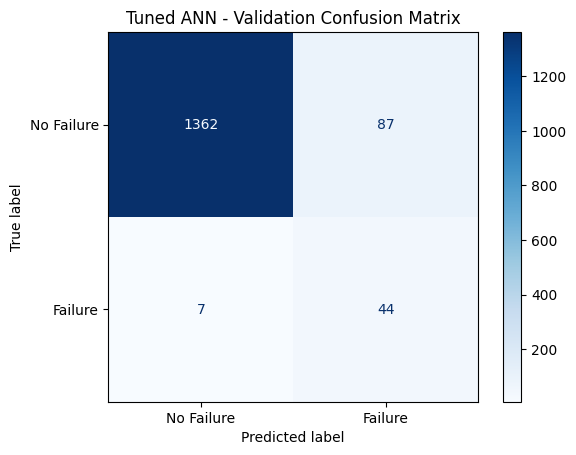

In [32]:

from sklearn.metrics import ConfusionMatrixDisplay
ann_tuned_pred = (ann_tuned_prob >= 0.5).astype(int)

cm = confusion_matrix(y_val, ann_tuned_pred)

tn, fp, fn, tp = cm.ravel()

print("Tuned ANN - Validation Errors")
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues")

plt.title("Tuned ANN - Validation Confusion Matrix")
plt.show()



**Findings:**
- Tuned ANN correctly detected 44 of 51 failures.
- Only 7 actual failures were missed.
- The model generated 87 false alarms at threshold 0.5.
- Recall is high (86.27%), but precision remains moderate (33.59%).
- Threshold and business-cost analysis are needed before final selection.



## 33. ANN Threshold Sensitivity

We evaluate different decision thresholds for the tuned ANN.

The goal is to understand how precision, recall, F1-score, and missed failures change without retraining the model.


In [33]:

ann_threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (ann_tuned_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    ann_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

ann_threshold_df = pd.DataFrame(ann_threshold_results)

display(ann_threshold_df.round(4))


,Threshold,Precision,Recall,F1,TP,FP,FN
0,0.1,0.1553,0.9804,0.2681,50,272,1
1,0.2,0.2034,0.9412,0.3345,48,188,3
2,0.3,0.2553,0.9412,0.4017,48,140,3
3,0.4,0.3007,0.9020,0.4510,46,107,5
4,0.5,0.3359,0.8627,0.4835,44,87,7
5,0.6,0.3805,0.8431,0.5244,43,70,8
6,0.7,0.4286,0.8235,0.5638,42,56,9
7,0.8,0.4884,0.8235,0.6131,42,44,9



**Findings:**
- Increasing the ANN threshold reduced false alarms.
- At threshold 0.8, ANN detected 42 of 51 failures.
- False positives decreased from 87 at threshold 0.5 to 44 at threshold 0.8.
- Threshold 0.8 achieved the highest F1-score (0.6131) among tested values.
- Final threshold selection requires business-cost analysis.



## 34. Adjusted Threshold Comparison

We compare tuned Random Forest and ANN at selected validation thresholds.

The objective is to examine the trade-off between failure detection, false alarms, and F1-score before cost-based model selection.


In [34]:

threshold_comparison = []

settings = [
    ("Tuned RF", best_rf_val_prob, 0.1),
    ("Tuned RF", best_rf_val_prob, 0.3),
    ("Tuned ANN", ann_tuned_prob, 0.8)
]

for name, prob, threshold in settings:
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    threshold_comparison.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(threshold_comparison).round(4))


,Model,Threshold,Precision,Recall,F1,TP,FP,FN
0,Tuned RF,0.1,0.4412,0.8824,0.5882,45,57,6
1,Tuned RF,0.3,0.6809,0.6275,0.6531,32,15,19
2,Tuned ANN,0.8,0.4884,0.8235,0.6131,42,44,9



**Findings:**
- Random Forest at threshold 0.1 achieved the highest recall (88.24%).
- Random Forest at threshold 0.3 achieved the highest F1-score (0.6531).
- ANN at threshold 0.8 detected 42 failures with 44 false alarms.
- Different thresholds create different operational trade-offs.
- Final model selection requires reliability and business-cost evaluation.



## 35. Class Imbalance Handling — Random Oversampling

We compare class-weighted Random Forest with a model trained using random oversampling.

- Oversampling is applied only to training data.
- Validation data remains unchanged.
- The same Random Forest settings are used, except for class weighting.
- PR-AUC is used to compare rare-failure prediction performance.


In [35]:

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=SEED)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_tree, y_train
)

print("Original Training Distribution:")
print(y_train.value_counts())

print("\nOversampled Training Distribution:")
print(pd.Series(y_train_ros).value_counts())

rf_ros = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=1,
    class_weight=None,
    random_state=SEED,
    n_jobs=-1
)

rf_ros.fit(X_train_ros, y_train_ros)

rf_ros_prob = rf_ros.predict_proba(X_val_tree)[:, 1]

print("\nValidation PR-AUC Comparison")
print("Class-weighted RF:",
      round(average_precision_score(y_val, best_rf_val_prob), 4))
print("Oversampled RF:",
      round(average_precision_score(y_val, rf_ros_prob), 4))


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Original Training Distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64

Oversampled Training Distribution:
Machine failure
0    6763
1    6763
Name: count, dtype: int64

Validation PR-AUC Comparison
Class-weighted RF: 0.6898
Oversampled RF: 0.6969



**Findings:**
- Random oversampling increased failure-class training samples from 237 to 6,763.
- Oversampling was applied only to training data.
- Validation PR-AUC improved slightly from 0.6898 to 0.6969.
- The improvement is small and requires further evaluation.
- Validation and test data remain unchanged.



## 36. Oversampling Performance Comparison

We compare class-weighted and oversampled Random Forest models using the same validation data.

We examine precision, recall, F1-score, and prediction errors at different thresholds.


In [36]:

ros_comparison = []

for name, prob in [
    ("Class-weighted RF", best_rf_val_prob),
    ("Oversampled RF", rf_ros_prob)
]:
    for threshold in [0.1, 0.3, 0.5]:
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

        ros_comparison.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

display(pd.DataFrame(ros_comparison).round(4))


,Model,Threshold,Precision,Recall,F1,TP,FP,FN
0,Class-weighted RF,0.1,0.4412,0.8824,0.5882,45,57,6
1,Class-weighted RF,0.3,0.6809,0.6275,0.6531,32,15,19
2,Class-weighted RF,0.5,0.8148,0.4314,0.5641,22,5,29
3,Oversampled RF,0.1,0.3636,0.8627,0.5116,44,77,7
4,Oversampled RF,0.3,0.6102,0.7059,0.6545,36,23,15
5,Oversampled RF,0.5,0.7647,0.5098,0.6118,26,8,25



**Findings:**
- Oversampling improved recall at thresholds 0.3 and 0.5.
- At threshold 0.3, missed failures decreased from 19 to 15, but false alarms increased from 15 to 23.
- Class weighting performed better at threshold 0.1.
- Oversampling slightly improved PR-AUC, but neither approach was consistently superior.
- Both models are retained for business-cost evaluation.



## Phase 2 Summary — ML and ANN Development

### Models Developed
- Logistic Regression, Random Forest, and TensorFlow/Keras ANN.
- All models used the same training and validation splits.
- Model tuning and selection used validation data only.

### Best Validation PR-AUC
- Tuned Logistic Regression: 0.3848
- Tuned Random Forest: 0.6898
- Oversampled Random Forest: 0.6969
- Tuned ANN: 0.7285

### Key Observations
- Logistic Regression tuning produced minimal improvement.
- Random Forest tuning improved PR-AUC and precision.
- ANN tuning improved PR-AUC from 0.6170 to 0.7285.
- Random oversampling slightly improved Random Forest PR-AUC.
- Adjusting thresholds substantially changed recall and false alarms.

### Important Decisions
- Retain tuned Logistic Regression, both Random Forest variants, and tuned ANN for further comparison.
- Do not select a final model based only on PR-AUC or the default threshold.
- Keep the test dataset untouched until final evaluation.
- Conduct a separate controlled ANN experiment to assess performance stability.



# Phase 3 — Model Evaluation and Reliability Audit

## 38. Confusion Matrix Comparison

We compare the prediction errors of all four model candidates using validation data.

The confusion matrices show correct predictions, false alarms, and missed failures at threshold 0.5.


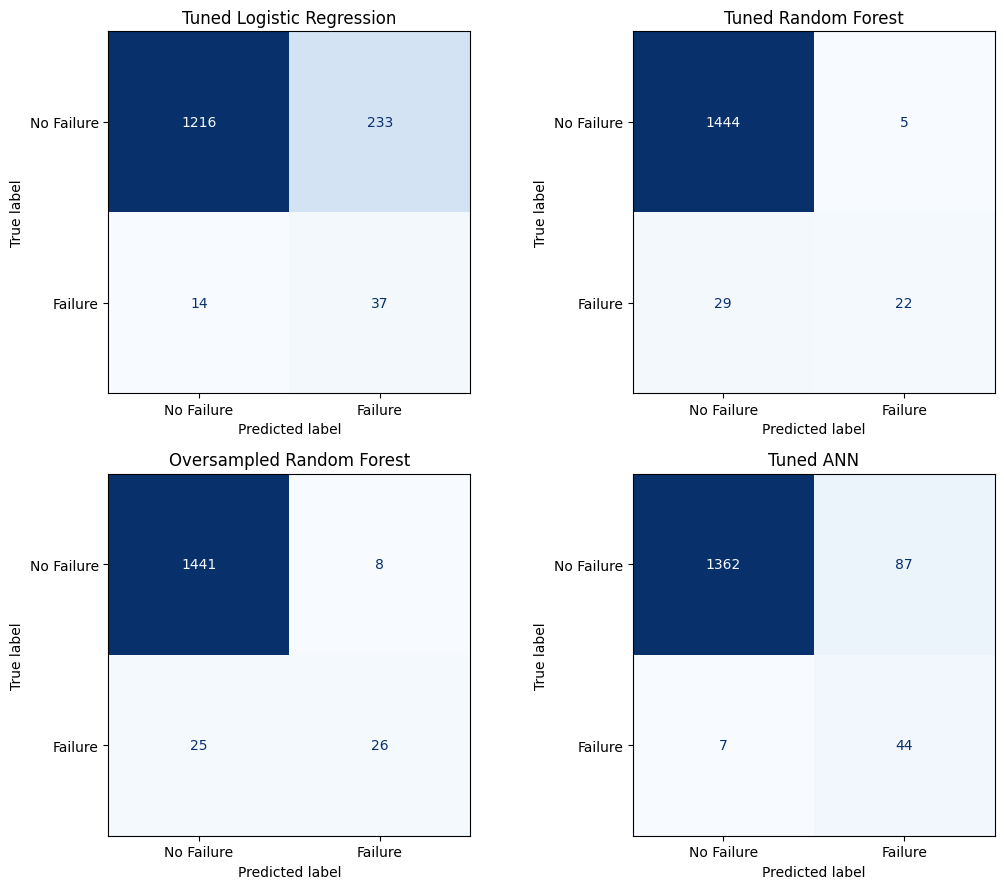

In [37]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

candidate_models = {
    "Tuned Logistic Regression": best_lr_val_prob,
    "Tuned Random Forest": best_rf_val_prob,
    "Oversampled Random Forest": rf_ros_prob,
    "Tuned ANN": ann_tuned_prob
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, prob) in zip(axes.flat, candidate_models.items()):
    pred = (prob >= 0.5).astype(int)
    cm = confusion_matrix(y_val, pred, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()



**Findings:**
- Tuned ANN detected the most failures (44) and missed only 7.
- Tuned Random Forest produced the fewest false alarms (5) but missed 29 failures.
- Oversampled Random Forest detected 26 failures with 8 false alarms.
- Logistic Regression generated the most false alarms (233).
- Threshold optimization is necessary before selecting the final model.



## 39. ROC and Precision–Recall Curve Comparison

We compare ROC and Precision–Recall curves for all four models using validation predictions.

ROC curves show class discrimination, while Precision–Recall curves focus on failure detection in our imbalanced dataset.


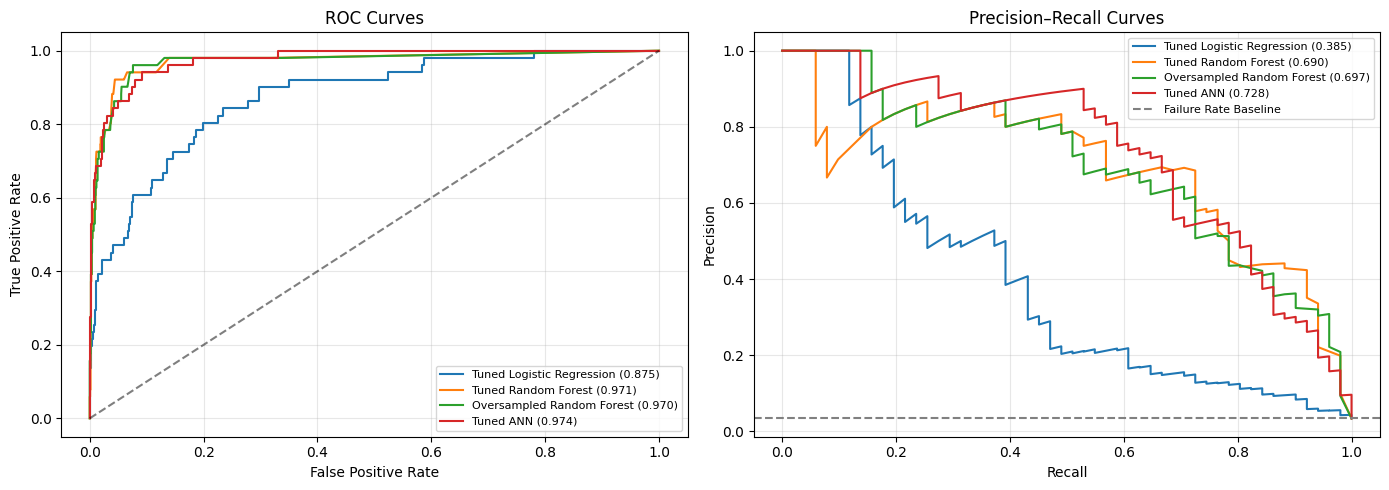

In [38]:

from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, prob in candidate_models.items():
    fpr, tpr, _ = roc_curve(y_val, prob)
    precision, recall, _ = precision_recall_curve(y_val, prob)

    roc_score = roc_auc_score(y_val, prob)
    pr_score = average_precision_score(y_val, prob)

    axes[0].plot(fpr, tpr, label=f"{name} ({roc_score:.3f})")
    axes[1].plot(recall, precision, label=f"{name} ({pr_score:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].axhline(y_val.mean(), linestyle="--", color="gray",
                label="Failure Rate Baseline")
axes[1].set_title("Precision–Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Findings:**
- Tuned ANN achieved the highest ROC-AUC (0.9745) and PR-AUC (0.7285).
- Random Forest models also showed strong ranking performance.
- Logistic Regression performed comparatively worse.
- Precision–Recall analysis is especially important because failures represent only 3.4% of records.
- Model selection must also consider prediction errors and business costs.



## 40. Hypothetical Maintenance Cost Analysis

We estimate the cost of false alarms and missed failures using illustrative assumptions.

- False Positive cost: ₹2,000 per unnecessary inspection.
- False Negative cost: ₹50,000 per missed failure.
- Total error cost = (FP × 2,000) + (FN × 50,000).

These costs are hypothetical and are used only to compare model decisions.


In [39]:

inspection_cost = 2000
missed_failure_cost = 50000

cost_results = []

for name, prob in candidate_models.items():
    for threshold in np.arange(0.05, 0.96, 0.05):
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

        total_cost = (
            fp * inspection_cost +
            fn * missed_failure_cost
        )

        cost_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "Total_Cost_INR": total_cost
        })

cost_df = pd.DataFrame(cost_results)

best_cost = (
    cost_df.sort_values(["Total_Cost_INR", "FN", "FP"])
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Total_Cost_INR")
)

display(best_cost.round(4))


,Model,Threshold,TP,FP,FN,Precision,Recall,F1,Total_Cost_INR
0,Oversampled Random Forest,0.05,49,127,2,0.2784,0.9608,0.4317,354000
3,Tuned Random Forest,0.05,48,106,3,0.3117,0.9412,0.4683,362000
1,Tuned ANN,0.30,48,140,3,0.2553,0.9412,0.4017,430000
2,Tuned Logistic Regression,0.45,40,277,11,0.1262,0.7843,0.2174,1104000



**Findings:**
- Oversampled Random Forest achieved the lowest hypothetical error cost (₹3,54,000) at threshold 0.05.
- It detected 49 of 51 failures, with 127 false alarms.
- Tuned Random Forest achieved ₹3,62,000, only ₹8,000 higher.
- ANN had the highest PR-AUC but not the lowest estimated cost.
- Results depend on assumed costs and tested thresholds.
- Final recommendations require cost sensitivity analysis.



## 41. Business Cost Sensitivity Analysis

We test different hypothetical missed-failure costs while keeping the false-alarm cost fixed.

This checks whether our preferred model and threshold remain stable when business assumptions change.


In [40]:

cost_scenarios = {
    "Low failure cost": 10000,
    "Medium failure cost": 50000,
    "High failure cost": 100000
}

sensitivity_results = []

for scenario, fn_cost in cost_scenarios.items():
    for name, prob in candidate_models.items():
        for threshold in np.arange(0.05, 0.96, 0.05):
            pred = (prob >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

            sensitivity_results.append({
                "Scenario": scenario,
                "Model": name,
                "Threshold": round(threshold, 2),
                "FP": fp,
                "FN": fn,
                "Total_Cost_INR": fp * 2000 + fn * fn_cost
            })

sensitivity_df = pd.DataFrame(sensitivity_results)

best_scenarios = (
    sensitivity_df.sort_values(
        ["Scenario", "Total_Cost_INR", "FN", "FP"]
    )
    .groupby("Scenario", as_index=False)
    .first()
)

display(best_scenarios)


,Scenario,Model,Threshold,FP,FN,Total_Cost_INR
0,High failure cost,Oversampled Random Forest,0.05,127,2,454000
1,Low failure cost,Tuned Random Forest,0.10,57,6,174000
2,Medium failure cost,Oversampled Random Forest,0.05,127,2,354000



**Findings:**
- At ₹10,000 per missed failure, tuned Random Forest had the lowest estimated cost (₹1,74,000).
- At ₹50,000 and ₹1,00,000, oversampled Random Forest had the lowest estimated cost.
- Higher missed-failure costs favored stronger failure detection.
- The preferred model changes with business assumptions.
- These findings are based on hypothetical costs and validation data.


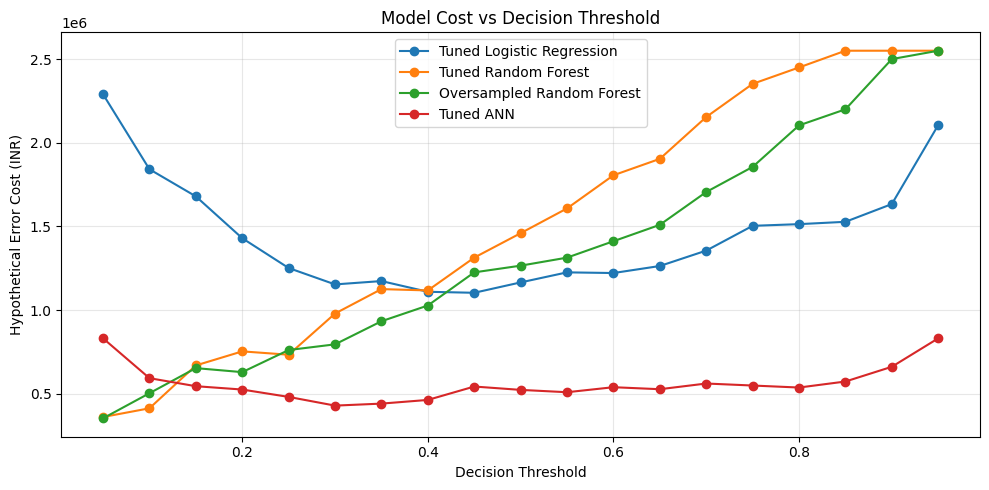

In [41]:

plt.figure(figsize=(10, 5))

for name in candidate_models:
    model_costs = cost_df[cost_df["Model"] == name]

    plt.plot(
        model_costs["Threshold"],
        model_costs["Total_Cost_INR"],
        marker="o",
        label=name
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Hypothetical Error Cost (INR)")
plt.title("Model Cost vs Decision Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Findings:**
- Oversampled Random Forest had the lowest tested cost (₹3,54,000) at threshold 0.05.
- Tuned Random Forest was close behind at ₹3,62,000.
- Higher thresholds generally increased Random Forest costs due to missed failures.
- ANN showed a lower-cost region around threshold 0.30.
- Final threshold selection needs a finer search, especially below 0.05.
- Costs are hypothetical and do not represent actual company expenses.



## 43. Refined Threshold Search

We examine smaller decision thresholds for both Random Forest models because their lowest observed costs occurred at 0.05.

We use the same validation data and hypothetical cost assumptions.


In [42]:

refined_results = []

for name, prob in [
    ("Tuned Random Forest", best_rf_val_prob),
    ("Oversampled Random Forest", rf_ros_prob)
]:
    for threshold in np.arange(0.005, 0.101, 0.005):
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

        refined_results.append({
            "Model": name,
            "Threshold": round(threshold, 3),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "Total_Cost_INR": (
                fp * inspection_cost +
                fn * missed_failure_cost
            )
        })

refined_df = pd.DataFrame(refined_results)

best_refined = (
    refined_df.sort_values(["Total_Cost_INR", "FN", "FP"])
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Total_Cost_INR")
)

display(best_refined.round(4))


,Model,Threshold,TP,FP,FN,Precision,Recall,Total_Cost_INR
1,Tuned Random Forest,0.085,47,64,4,0.4234,0.9216,328000
0,Oversampled Random Forest,0.055,49,116,2,0.2970,0.9608,332000



**Findings:**
- Tuned Random Forest achieved the lowest refined validation cost (₹3,28,000) at threshold 0.085.
- It detected 47 failures, missed 4, and generated 64 false alarms.
- Oversampled Random Forest achieved ₹3,32,000 at threshold 0.055.
- The cost difference is only ₹4,000, so the models remain competitive.
- These are validation-based results using hypothetical costs, not real maintenance expenses.




## 44. Complete Validation Threshold Search

We evaluate all distinct prediction thresholds for the four candidate models.

This identifies the lowest hypothetical error cost achievable on validation data without relying on a fixed threshold grid.

The test set remains untouched.


In [43]:

complete_threshold_results = []

for name, prob in candidate_models.items():
    thresholds = np.unique(np.r_[0, prob, 1, np.nextafter(1.0, 2.0)])

    for threshold in thresholds:
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()

        complete_threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "Cost_INR": fp * inspection_cost + fn * missed_failure_cost
        })

complete_threshold_df = pd.DataFrame(complete_threshold_results)

best_thresholds = (
    complete_threshold_df
    .sort_values(["Cost_INR", "FN", "FP", "Threshold"],
                 ascending=[True, True, True, False])
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Cost_INR")
)

display(best_thresholds.round(4))


,Model,Threshold,TP,FP,FN,Precision,Recall,F1,Cost_INR
0,Oversampled Random Forest,0.0581,49,110,2,0.3082,0.9608,0.4667,320000
3,Tuned Random Forest,0.0850,47,64,4,0.4234,0.9216,0.5802,328000
1,Tuned ANN,0.3113,48,133,3,0.2652,0.9412,0.4138,416000
2,Tuned Logistic Regression,0.3946,43,338,8,0.1129,0.8431,0.1991,1076000



## 45. ANN with Random Oversampling

We test whether random oversampling improves ANN performance compared with class weighting.

We apply oversampling only to the training data and keep validation data unchanged.

The ANN architecture and training settings remain the same as our tuned ANN. Class weights are not used for the oversampled version.


In [44]:

from imblearn.over_sampling import RandomOverSampler

# Oversample training data only
ros_ann = RandomOverSampler(random_state=SEED)

X_train_ann_ros, y_train_ann_ros = ros_ann.fit_resample(
    X_train_scaled, y_train
)

# Rebuild the same tuned ANN architecture
tf.keras.utils.set_random_seed(SEED)

ann_ros = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

ann_ros.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="roc_auc"),
             tf.keras.metrics.AUC(curve="PR", name="pr_auc")]
)

early_stop_ros = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history_ann_ros = ann_ros.fit(
    X_train_ann_ros, y_train_ann_ros,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop_ros],
    verbose=0
)

# Compare both ANN models on unchanged validation data
ann_ros_prob = ann_ros.predict(X_val_scaled, verbose=0).ravel()

ann_comparison = pd.DataFrame([
    {
        "Model": "ANN with Class Weights",
        "ROC_AUC": roc_auc_score(y_val, ann_tuned_prob),
        "PR_AUC": average_precision_score(y_val, ann_tuned_prob)
    },
    {
        "Model": "ANN with Oversampling",
        "ROC_AUC": roc_auc_score(y_val, ann_ros_prob),
        "PR_AUC": average_precision_score(y_val, ann_ros_prob)
    }
])

print("Oversampled training class distribution:")
print(pd.Series(y_train_ann_ros).value_counts())

print("\nANN comparison:")
display(ann_comparison.round(4))


C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


Oversampled training class distribution:
Machine failure
0    6763
1    6763
Name: count, dtype: int64

ANN comparison:


,Model,ROC_AUC,PR_AUC
0,ANN with Class Weights,0.9745,0.7285
1,ANN with Oversampling,0.9713,0.7421



**Findings:**
- ANN with oversampling achieved PR-AUC 0.7421, compared with 0.7285 using class weights.
- ROC-AUC decreased slightly from 0.9745 to 0.9713.
- Oversampling showed a small improvement in failure-focused ranking performance.
- Further threshold and error-cost analysis is needed before choosing between the two ANNs.
- The results come from a single training run and do not establish consistent superiority.



## 46. ANN Imbalance Handling — Cost Comparison

We compare class-weighted and oversampled ANN models using validation-selected thresholds.

Both models use the same hypothetical error costs:
- False alarm: ₹2,000
- Missed failure: ₹50,000

The comparison includes precision, recall, missed failures, false alarms, and total error cost.


In [45]:

ann_cost_results = []

ann_versions = {
    "ANN with Class Weights": ann_tuned_prob,
    "ANN with Oversampling": ann_ros_prob
}

for name, prob in ann_versions.items():
    thresholds = np.unique(np.r_[0, prob, 1, np.nextafter(1.0, 2.0)])

    for threshold in thresholds:
        pred = (prob >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        ann_cost_results.append({
            "Model": name,
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "F1": f1_score(y_val, pred, zero_division=0),
            "Cost_INR": (
                fp * inspection_cost + fn * missed_failure_cost
            )
        })

ann_cost_df = pd.DataFrame(ann_cost_results)

best_ann_cost = (
    ann_cost_df
    .sort_values(["Cost_INR", "FN", "FP", "Threshold"],
                 ascending=[True, True, True, False])
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Cost_INR")
)

display(best_ann_cost.round(4))


,Model,Threshold,TP,FP,FN,Precision,Recall,F1,Cost_INR
0,ANN with Class Weights,0.3113,48,133,3,0.2652,0.9412,0.4138,416000
1,ANN with Oversampling,0.0810,47,127,4,0.2701,0.9216,0.4178,454000



**Findings:**
- Oversampling increased ANN PR-AUC from 0.7285 to 0.7421.
- However, class-weighted ANN achieved a lower hypothetical validation cost (₹4,16,000 vs ₹4,54,000).
- Class-weighted ANN detected 48 failures, compared with 47 using oversampling.
- Oversampling improved ranking performance slightly but did not improve cost-based decisions.
- Class weighting remains the preferred ANN approach under the current assumptions.



## 47. Missed Failure Analysis

We investigate the actual failure records missed by our two leading Random Forest models.

This helps us understand difficult failure cases and identify limitations in the models.


In [46]:

leading_models = [
    ("Tuned RF", best_rf_val_prob, 0.085),
    ("Oversampled RF", rf_ros_prob, 0.0581)
]

for name, prob, threshold in leading_models:
    pred = (prob >= threshold).astype(int)
    missed_mask = (y_val.to_numpy() == 1) & (pred == 0)

    missed = X_val.iloc[np.where(missed_mask)[0]].copy()
    missed["Failure_Score"] = prob[missed_mask]

    print(f"\n{name} — Missed Failures: {len(missed)}")
    display(missed.round(3))



Tuned RF — Missed Failures: 4


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Score
2671,M,299.7,309.3,1399,41.9,221,0.020
7087,L,300.6,310.3,1648,30.5,217,0.055
3695,L,302.2,311.3,1530,37.3,207,0.020
8506,L,298.4,309.6,1710,27.3,163,0.000



Oversampled RF — Missed Failures: 3


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Score
2671,M,299.7,309.3,1399,41.9,221,0.025
7087,L,300.6,310.3,1648,30.5,217,0.058
8506,L,298.4,309.6,1710,27.3,163,0.000



## 48. Exact Threshold Verification

We verify the missed-failure counts using the exact validation-selected thresholds to avoid rounding errors.


In [47]:

for name, prob in [
    ("Tuned Random Forest", best_rf_val_prob),
    ("Oversampled Random Forest", rf_ros_prob)
]:
    threshold = best_thresholds.loc[
        best_thresholds["Model"] == name, "Threshold"
    ].iloc[0]

    pred = (prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    missed_ids = X_val.index[
        (y_val.to_numpy() == 1) & (pred == 0)
    ].tolist()

    print(f"\n{name}")
    print(f"Exact threshold: {threshold:.10f}")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
    print("Missed records:", missed_ids)



Tuned Random Forest
Exact threshold: 0.0850000000
TP: 47, FP: 64, FN: 4, TN: 1385
Missed records: [2671, 7087, 3695, 8506]

Oversampled Random Forest
Exact threshold: 0.0580690315
TP: 49, FP: 110, FN: 2, TN: 1339
Missed records: [2671, 8506]



**Findings:**
- Exact threshold verification confirmed the original validation results.
- Tuned RF missed 4 failures at threshold 0.085.
- Oversampled RF missed 2 failures at threshold 0.058069.
- Both models missed records 2671 and 8506.
- The earlier discrepancy was caused by threshold rounding.
- Full-precision thresholds should be retained for final evaluation.



## 49. Training vs Validation Performance

We compare training and validation ROC-AUC and PR-AUC for our leading models.

A large performance gap may indicate overfitting. Training data is evaluated in its original distribution without oversampling.


In [48]:

reliability_models = {
    "Tuned RF": (
        best_rf.predict_proba(X_train_tree)[:, 1],
        best_rf_val_prob
    ),
    "Oversampled RF": (
        rf_ros.predict_proba(X_train_tree)[:, 1],
        rf_ros_prob
    ),
    "Tuned ANN": (
        ann_tuned.predict(X_train_scaled, verbose=0).ravel(),
        ann_tuned_prob
    ),
    "Oversampled ANN": (
        ann_ros.predict(X_train_scaled, verbose=0).ravel(),
        ann_ros_prob
    )
}

reliability_results = []

for name, (train_prob, val_prob) in reliability_models.items():
    train_pr = average_precision_score(y_train, train_prob)
    val_pr = average_precision_score(y_val, val_prob)

    reliability_results.append({
        "Model": name,
        "Train_ROC_AUC": roc_auc_score(y_train, train_prob),
        "Val_ROC_AUC": roc_auc_score(y_val, val_prob),
        "Train_PR_AUC": train_pr,
        "Val_PR_AUC": val_pr,
        "PR_AUC_Gap": train_pr - val_pr
    })

reliability_df = pd.DataFrame(reliability_results)
display(reliability_df.round(4))


,Model,Train_ROC_AUC,Val_ROC_AUC,Train_PR_AUC,Val_PR_AUC,PR_AUC_Gap
0,Tuned RF,1.0000,0.9712,1.0000,0.6898,0.3102
1,Oversampled RF,1.0000,0.9702,1.0000,0.6969,0.3031
2,Tuned ANN,0.9878,0.9745,0.8309,0.7285,0.1024
3,Oversampled ANN,0.9969,0.9713,0.9227,0.7421,0.1806



**Findings:**
- Both Random Forest models achieved perfect training PR-AUC (1.0), but validation PR-AUC was around 0.69.
- This large gap suggests potential overfitting.
- Class-weighted ANN showed the smallest PR-AUC gap (0.1024).
- Oversampled ANN achieved higher training PR-AUC but also showed a larger validation gap (0.1806).
- The ANN models showed smaller training-validation gaps than Random Forest.
- Final generalization must be checked using the untouched test set.



# Phase 3 — Evaluation and Reliability Summary

### Model Performance
- Class-weighted ANN achieved ROC-AUC 0.9745 and PR-AUC 0.7285.
- Oversampled ANN achieved the highest validation PR-AUC (0.7421).
- Both Random Forest models achieved PR-AUC around 0.69.
- Class-weighted ANN showed the smallest training-validation PR-AUC gap (0.1024).

### Threshold and Cost Analysis
- Hypothetical false-positive cost: ₹2,000.
- Hypothetical false-negative cost: ₹50,000.
- Oversampled RF achieved the lowest validation error cost (₹3,20,000) at threshold 0.0580690315.
- Tuned RF achieved ₹3,28,000 at threshold 0.085.
- Class-weighted ANN achieved ₹4,16,000.
- Oversampled ANN achieved ₹4,54,000.

### Reliability Findings
- Oversampled RF missed only 2 of 51 actual failures.
- Both Random Forest models showed large training-validation performance gaps, suggesting potential overfitting.
- ANN models showed smaller gaps.
- Some actual failures were missed despite relatively high tool wear.

### Conclusion
- Oversampled RF is the provisional cost-based choice.
- Class-weighted ANN remains a strong alternative because of its ranking performance and smaller training-validation gap.
- Costs are hypothetical, and thresholds were selected using validation data.
- Final model selection and evaluation on the untouched test set are still pending.



# Phase 4 — Controlled ANN Experiment

## 51. Research Hypothesis and Experiment Design

**Research Question:** Does changing the learning rate improve ANN performance for machine failure prediction?

**Hypothesis:** A lower learning rate may improve ANN generalization and PR-AUC compared with the baseline learning rate of 0.001.

### Experiment Setup
- Model: Class-weighted ANN
- Architecture: 64 → 32 → Dropout(0.2) → 1
- Optimizer: Adam
- Learning rates: 0.001 (baseline) and 0.0005 (experimental)
- Loss: Binary Crossentropy
- Batch size: 32
- Maximum epochs: 50
- Early stopping: Validation loss, patience 7
- Data: Same training and validation splits
- Preprocessing: Same training-fitted scaler and encoder
- Random seeds: 42, 123, 2026

**Controlled Variable:** Learning rate only.

**Evaluation:** Validation ROC-AUC, PR-AUC, and variability across seeds.

**Expected Outcome:** Determine whether the learning-rate change provides a consistent improvement rather than a one-run advantage.



## 52. Controlled ANN Learning Rate Experiment

We train the same ANN using two learning rates (0.001 and 0.0005) across three random seeds.

All other settings remain unchanged. We compare validation ROC-AUC, PR-AUC, and training epochs.


In [49]:

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
ann_class_weights = dict(zip(classes.tolist(), weights.tolist()))

experiment_results = []

for seed in [42, 123, 2026]:
    for lr in [0.001, 0.0005]:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dropout(0.2),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss="binary_crossentropy"
        )

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        )

        history_exp = model.fit(
            X_train_scaled, y_train,
            validation_data=(X_val_scaled, y_val),
            epochs=50,
            batch_size=32,
            class_weight=ann_class_weights,
            callbacks=[early_stop],
            verbose=0
        )

        prob = model.predict(X_val_scaled, verbose=0).ravel()

        experiment_results.append({
            "Seed": seed,
            "Learning_Rate": lr,
            "Epochs": len(history_exp.history["loss"]),
            "ROC_AUC": roc_auc_score(y_val, prob),
            "PR_AUC": average_precision_score(y_val, prob)
        })

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df.round(4))


,Seed,Learning_Rate,Epochs,ROC_AUC,PR_AUC
0,42,0.0010,46,0.9745,0.7285
1,42,0.0005,35,0.9636,0.6043
2,123,0.0010,24,0.9630,0.6051
3,123,0.0005,48,0.9695,0.6522
4,2026,0.0010,25,0.9625,0.6208
5,2026,0.0005,46,0.9686,0.6674



**Findings:**
- Six ANN runs were completed using two learning rates and three random seeds.
- Learning rate 0.001 achieved the highest individual PR-AUC (0.7285).
- Learning rate 0.0005 performed better for seeds 123 and 2026.
- Performance changed across random seeds, indicating training variability.
- Average performance and standard deviation are needed to evaluate the hypothesis.



## 53. Learning Rate Experiment — Mean and Variability

We summarize validation ROC-AUC and PR-AUC across three seeds for each learning rate.

Mean performance measures the average result, while standard deviation measures variability between runs.


In [50]:

experiment_summary = (
    experiment_df.groupby("Learning_Rate")
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Std_ROC_AUC=("ROC_AUC", "std"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std"),
        Mean_Epochs=("Epochs", "mean")
    )
    .reset_index()
)

display(experiment_summary.round(4))


,Learning_Rate,Mean_ROC_AUC,Std_ROC_AUC,Mean_PR_AUC,Std_PR_AUC,Mean_Epochs
0,0.0005,0.9673,0.0032,0.6413,0.0329,43.0000
1,0.0010,0.9666,0.0068,0.6515,0.0672,31.6667



**Findings:**
- Learning rate 0.001 achieved slightly higher mean PR-AUC (0.6515 vs 0.6413).
- Learning rate 0.0005 showed lower PR-AUC variability (0.0329 vs 0.0672).
- The lower learning rate required more epochs on average (43 vs 31.67).
- The hypothesis that a lower learning rate improves average PR-AUC was not supported.
- Results are based on three seeds, so further repetitions would be needed for stronger conclusions.



## 54. Learning Rate Performance Across Seeds

We visualize validation PR-AUC for both learning rates across the same random seeds.

This helps compare performance variation and identify whether improvements are consistent.


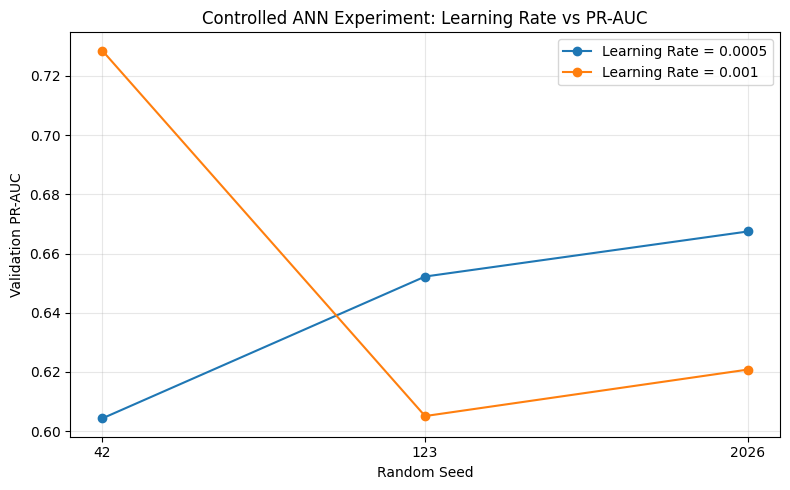

In [51]:

plt.figure(figsize=(8, 5))

for lr, group in experiment_df.groupby("Learning_Rate"):
    group = group.sort_values("Seed")
    plt.plot(
        group["Seed"].astype(str),
        group["PR_AUC"],
        marker="o",
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Random Seed")
plt.ylabel("Validation PR-AUC")
plt.title("Controlled ANN Experiment: Learning Rate vs PR-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




**Findings:**
- Learning rate 0.001 achieved the highest PR-AUC at seed 42.
- Learning rate 0.0005 performed better at seeds 123 and 2026.
- The baseline had slightly higher average PR-AUC (0.6515 vs 0.6413).
- The lower learning rate showed less variability across the three seeds.
- No learning rate consistently outperformed the other.



# Phase 4 — Controlled ANN Experiment Summary

### Research Question
Does reducing the ANN learning rate from 0.001 to 0.0005 improve machine failure prediction?

### Experimental Method
- Changed only the learning rate.
- Kept ANN architecture, Adam optimizer, loss, class weights, preprocessing, batch size, and early stopping fixed.
- Used three random seeds: 42, 123, and 2026.
- Completed six training runs.
- Evaluated using validation ROC-AUC and PR-AUC.

### Results
- Learning rate 0.001: Mean PR-AUC 0.6515, standard deviation 0.0672.
- Learning rate 0.0005: Mean PR-AUC 0.6413, standard deviation 0.0329.
- Mean PR-AUC decreased by 0.0102 with the lower learning rate.
- Mean ROC-AUC increased slightly from 0.9666 to 0.9673.
- Average training epochs increased from 31.67 to 43.

### Hypothesis Evaluation
The hypothesis that a lower learning rate improves average PR-AUC was not supported.

The lower learning rate reduced variability across seeds but did not improve average failure-focused ranking performance.

### Limitations
- Only three random seeds were tested.
- Results are based on one validation split.
- Training duration differed because of early stopping.
- The experiment does not establish that either learning rate is universally superior.

### Conclusion
Learning rate affects ANN training performance and stability. However, reducing the learning rate did not consistently improve validation PR-AUC.

The original learning rate of 0.001 remains a reasonable choice for the class-weighted ANN.



# Phase 5 — Business Interpretation and Maintenance Recommendations

## 56. Risk-Based Maintenance Strategy

### Business Objective
Use machine failure risk scores to help maintenance teams prioritize inspections and reduce missed failures.

### Proposed Decision System
- **Inspection Required:** Model score is at or above the selected threshold.
- **Routine Monitoring:** Model score is below the selected threshold.

### Current Candidate
- Model: Oversampled Random Forest
- Validation-selected threshold: 0.0580690315
- Validation recall: 96.08%
- Validation false alarms: 110
- Hypothetical validation error cost: ₹3,20,000

### Maintenance Recommendations
- Flagged machines should be reviewed by maintenance personnel.
- Inspect relevant sensor readings before deciding on maintenance actions.
- Unflagged machines should continue routine monitoring.
- The system supports maintenance decisions; it does not automatically diagnose faults or stop machines.

### Assumptions and Limitations
- The threshold depends on hypothetical inspection and missed-failure costs.
- Model scores are not guaranteed to be calibrated probabilities.
- The dataset contains independent records rather than machine histories.
- These recommendations require real-world validation before deployment.



## 57. Generate Risk-Based Maintenance Recommendations

We use the oversampled Random Forest to classify machine records into two inspection categories.

- Inspection Required: Score >= selected threshold.
- Routine Monitoring: Score < selected threshold.

The threshold was selected using validation data and hypothetical maintenance costs. This is a demonstration of the proposed decision system, not a deployed solution.


In [52]:

# Retrieve the exact validation-selected threshold
selected_threshold = best_thresholds.loc[
    best_thresholds["Model"] == "Oversampled Random Forest",
    "Threshold"
].iloc[0]

# Build maintenance recommendations
maintenance_df = X_val.copy()
maintenance_df["Failure_Score"] = rf_ros_prob

maintenance_df["Recommendation"] = np.where(
    maintenance_df["Failure_Score"] >= selected_threshold,
    "Inspection Required",
    "Routine Monitoring"
)

print(f"Selected threshold: {selected_threshold:.10f}")

print("\nMaintenance recommendation counts:")
print(maintenance_df["Recommendation"].value_counts())

print("\nSample inspection recommendations:")
display(
    maintenance_df[
        maintenance_df["Recommendation"] == "Inspection Required"
    ].sort_values("Failure_Score", ascending=False).head(10).round(4)
)


Selected threshold: 0.0580690315

Maintenance recommendation counts:
Recommendation
Routine Monitoring     1341
Inspection Required     159
Name: count, dtype: int64

Sample inspection recommendations:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Score,Recommendation
4495,L,302.6,310.4,1359,57.2,67,0.9197,Inspection Required
7011,L,300.5,310.5,2633,12.2,17,0.8900,Inspection Required
248,L,298.0,308.3,1362,56.8,216,0.8700,Inspection Required
380,L,297.5,308.3,2564,12.8,127,0.8650,Inspection Required
4748,L,303.2,311.2,1363,46.7,29,0.8645,Inspection Required
249,L,298.0,308.3,1405,56.2,218,0.8600,Inspection Required
4661,L,303.3,311.3,1350,48.1,32,0.8593,Inspection Required
2444,L,299.2,308.6,1267,68.2,76,0.8400,Inspection Required
4302,L,301.7,310.1,2695,12.6,10,0.8350,Inspection Required
6497,L,300.8,309.9,1312,65.3,192,0.8100,Inspection Required



**Findings:**
- 159 of 1,500 validation records were flagged for inspection (10.6%).
- The model correctly flagged 49 actual failures and generated 110 false alarms.
- Routine monitoring included 1,339 healthy records and 2 missed failures.
- High-scoring records showed different combinations of rotational speed, torque, and tool wear.
- The system provides inspection recommendations, not confirmed fault diagnoses.



## 58. Sensor Feature Importance Analysis

We use permutation importance to identify which features contribute most to the oversampled Random Forest's validation predictions.

Feature importance measures model reliance, not a causal relationship with machine failure.


,Feature,Importance,Std
3,num__Torque [Nm],0.4056,0.0132
2,num__Rotational speed [rpm],0.3913,0.0191
0,num__Air temperature [K],0.3673,0.0405
4,num__Tool wear [min],0.2402,0.0128
1,num__Process temperature [K],0.1174,0.0474
6,cat__Type_L,0.0005,0.0084
5,cat__Type_H,-0.0028,0.0085
7,cat__Type_M,-0.0115,0.0150


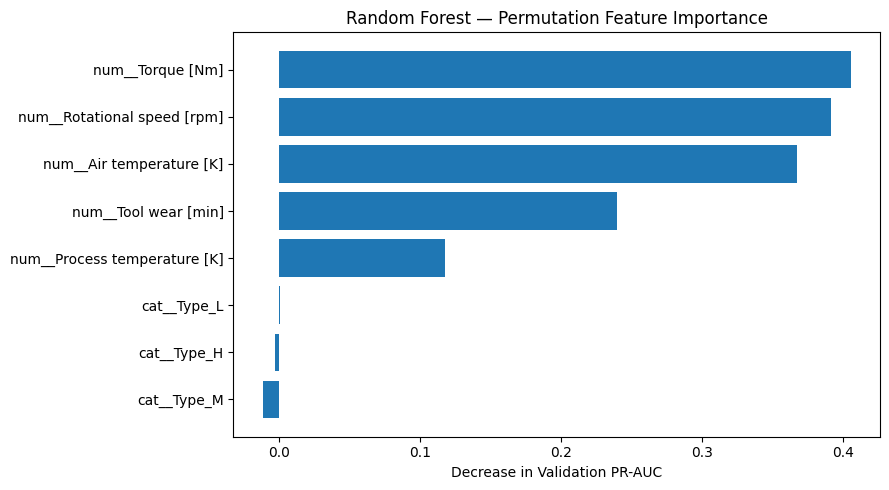

In [53]:

from sklearn.inspection import permutation_importance

importance = permutation_importance(
    rf_ros,
    X_val_tree,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1
)

feature_names = preprocessor_tree.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Decrease in Validation PR-AUC")
plt.title("Random Forest — Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



**Findings:**
- Torque (0.4056) and rotational speed (0.3913) showed the highest permutation importance.
- Air temperature (0.3673) and tool wear (0.2402) were also important.
- Process temperature showed lower individual importance (0.1174).
- Encoded machine Type columns showed minimal or slightly negative importance.
- Correlated sensors and separately shuffled one-hot columns limit interpretation.
- Feature importance indicates model reliance, not the cause of machine failure.



## 59. Sensor Profile of Maintenance Recommendations

We compare sensor readings between inspection-required and routine-monitoring records.

This helps identify general operating patterns associated with the model's recommendations.

The results describe model-selected groups and do not establish failure causes.


In [54]:

sensor_profile = (
    maintenance_df
    .groupby("Recommendation")[sensor_cols]
    .median()
    .T
)

sensor_profile["Difference"] = (
    sensor_profile["Inspection Required"]
    - sensor_profile["Routine Monitoring"]
)

display(sensor_profile.round(2))


Recommendation,Inspection Required,Routine Monitoring,Difference
Air temperature [K],301.2,300.0,1.2
Process temperature [K],310.6,310.0,0.6
Rotational speed [rpm],1372.0,1518.0,-146.0
Torque [Nm],48.6,38.9,9.7
Tool wear [min],172.0,105.0,67.0



**Findings:**
- Inspection-required records showed higher median torque (48.6 vs 38.9 Nm).
- Their median rotational speed was lower (1372 vs 1518 rpm).
- Median tool wear was higher (172 vs 105 minutes).
- Air and process temperatures were slightly higher in the inspection group.
- These differences help describe model-selected risk patterns but do not establish causation.
- Individual records may show different sensor combinations.



## 60. Maintenance Decision Outcome Summary

We compare the proposed inspection recommendations against actual machine failure labels.

This summarizes correctly identified failures, unnecessary inspections, and missed failures on validation data.

The results are based on a hypothetical decision-support system.


In [55]:

maintenance_outcomes = maintenance_df.copy()
maintenance_outcomes["Actual_Failure"] = y_val

outcome_table = pd.crosstab(
    maintenance_outcomes["Recommendation"],
    maintenance_outcomes["Actual_Failure"]
)

outcome_table = outcome_table.rename(
    columns={0: "No Failure", 1: "Failure"}
)

display(outcome_table)

print("\nInspection Rate:",
      f"{(maintenance_df['Recommendation'] == 'Inspection Required').mean():.2%}")

print("Failure Detection Rate:",
      f"{49 / 51:.2%}")


Actual_Failure,No Failure,Failure
Recommendation,,
Inspection Required,110,49
Routine Monitoring,1339,2



Inspection Rate: 10.60%
Failure Detection Rate: 96.08%



**Findings:**
- The system flagged 159 of 1,500 validation records for inspection (10.60%).
- It correctly identified 49 of 51 failures (96.08% recall).
- There were 110 false alarms and 2 missed failures.
- The system prioritizes failure detection but creates additional inspection workload.
- Results are based on validation data and hypothetical maintenance assumptions.



## 61. Business Recommendations and Deployment Limitations

### Recommended Maintenance Workflow
1. Collect machine type, temperature, rotational speed, torque, and tool wear readings.
2. Apply the same preprocessing used during training.
3. Generate a failure risk score using the selected model.
4. Flag records above the selected threshold for maintenance review.
5. Let maintenance personnel inspect flagged machines before taking action.
6. Continue routine monitoring of unflagged machines.

### Key Sensor Findings
- Torque and rotational speed were the most important individual features in permutation analysis.
- Flagged records generally showed higher torque, higher tool wear, and lower rotational speed.
- Different sensor combinations can lead to high model scores.
- These are associations and model patterns, not confirmed failure causes.

### Deployment Limitations
- The dataset is synthetic and may not represent real factory conditions.
- Records do not provide continuous machine histories.
- Validation-selected thresholds may not perform equally well on new data.
- Class imbalance and potential overfitting remain important concerns.
- Model scores are not necessarily calibrated failure probabilities.
- Hypothetical maintenance costs must be replaced with real operational estimates.
- Maintenance staff should review alerts rather than relying on automatic shutdown decisions.

### Future Improvements
- Validate performance on real factory sensor data.
- Collect time-series readings and maintenance histories.
- Evaluate probability calibration and monitor model performance over time.
- Reassess thresholds using actual inspection and failure costs.
- Investigate missed failures and collect additional relevant sensor information.



# Phase 5 — Business Interpretation Summary

### Maintenance Decision System
- Developed a proposed inspection-priority system using Oversampled Random Forest.
- Used the validation-selected threshold of 0.0580690315.
- Flagged 159 of 1,500 validation records (10.60%).
- Correctly detected 49 of 51 failures (96.08% recall).
- Generated 110 false alarms and missed 2 failures.

### Important Sensor Patterns
- Torque and rotational speed showed the highest permutation importance.
- Inspection-required records had higher median torque (48.6 vs 38.9 Nm).
- Median tool wear was higher (172 vs 105 minutes).
- Median rotational speed was lower (1372 vs 1518 rpm).
- These are observed associations, not confirmed causes of failure.

### Business Impact
- The system could help maintenance teams prioritize machine inspections.
- Under hypothetical costs of ₹2,000 per false alarm and ₹50,000 per missed failure, estimated validation error cost was ₹3,20,000.
- High failure detection comes with additional inspection workload.

### Limitations
- The dataset is synthetic rather than real factory data.
- Random Forest showed a large training-validation performance gap.
- Model scores may not represent calibrated probabilities.
- The selected threshold depends on hypothetical costs.
- Validation performance may not generalize to unseen factory conditions.

### Recommendations
- Use model alerts as decision support, not automatic shutdown commands.
- Validate predictions using real operational data.
- Replace hypothetical costs with actual maintenance expenses.
- Monitor false alarms, missed failures, and model performance after deployment.

### Conclusion
Oversampled Random Forest is the provisional cost-based choice, while class-weighted ANN remains a strong alternative due to its ranking performance and smaller training-validation gap.

Final model selection and independent test evaluation are still pending.



# Final Model Selection and Test Evaluation

## 63. Final Model Selection

### Selected Model
Oversampled Random Forest

### Selection Criteria
- Lowest hypothetical validation error cost: ₹3,20,000.
- Validation recall: 96.08%.
- Correctly detected 49 of 51 failures.
- Validation PR-AUC: 0.6969.
- Selected threshold: 0.0580690315.

### Comparison with ANN
- Class-weighted ANN achieved higher validation PR-AUC (0.7285).
- However, its lowest hypothetical validation error cost was ₹4,16,000.
- Oversampled ANN achieved PR-AUC 0.7421 but had a higher estimated cost of ₹4,54,000.

### Model Selection Rationale
The selected Random Forest provided the lowest estimated error cost under the stated hypothetical maintenance costs.

It is preferred for this cost-based decision scenario, rather than because it achieved the highest PR-AUC.

### Limitations
- Random Forest showed a large training-validation PR-AUC gap.
- The estimated cost depends on hypothetical assumptions.
- The selected threshold was optimized on validation data.
- Independent test evaluation is required to assess generalization.

### Final Evaluation Rule
The selected model and full-precision threshold will remain fixed during test evaluation. No further model tuning or threshold optimization will use test results.



## 64. Independent Test Evaluation

We evaluate the selected Oversampled Random Forest on the untouched test dataset.

The model and threshold were selected using validation data. Both remain fixed during test evaluation.

We calculate precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix values, and hypothetical maintenance error cost.


In [56]:

# Apply existing training-fitted preprocessing
X_test_tree = preprocessor_tree.transform(X_test)

# Use the selected model and exact validation threshold
final_model = rf_ros
final_threshold = best_thresholds.loc[
    best_thresholds["Model"] == "Oversampled Random Forest",
    "Threshold"
].iloc[0]

# Predict on untouched test data
test_prob = final_model.predict_proba(X_test_tree)[:, 1]
test_pred = (test_prob >= final_threshold).astype(int)

# Calculate test metrics
tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

test_results = pd.DataFrame([{
    "Model": "Oversampled Random Forest",
    "Threshold": final_threshold,
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC": average_precision_score(y_test, test_prob),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn,
    "Hypothetical_Cost_INR": (
        fp * inspection_cost + fn * missed_failure_cost
    )
}])

display(test_results.round(4))


,Model,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,FN,TN,Hypothetical_Cost_INR
0,Oversampled Random Forest,0.0581,0.2682,0.9412,0.4174,0.9593,0.744,48,131,3,1318,412000



**Findings:**
- The selected Oversampled RF achieved 94.12% recall and 0.7440 PR-AUC on the independent test set.
- It detected 48 of 51 failures, with 131 false alarms and 3 missed failures.
- Precision decreased from 30.82% on validation to 26.82% on test.
- Hypothetical error cost increased from ₹3,20,000 to ₹4,12,000.
- Test PR-AUC increased slightly, while ROC-AUC and threshold-specific F1 decreased.
- The fixed validation-selected threshold was used without test-based tuning.
- Results indicate strong failure detection but substantial false-alarm workload.



## 65. Final Test Confusion Matrix

We visualize the final selected model's predictions on the independent test dataset using the frozen validation-selected threshold.

This shows correct predictions, false alarms, and missed failures.



cm_test = confusion_matrix(y_test, test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues", colorbar=False)

plt.title("Final Oversampled RF — Independent Test")
plt.tight_layout()
plt.show()



# Final Results and Submission Preparation

## 66. Export Model Comparison Results

We create a CSV containing validation performance for all model candidates and the independent test performance of the selected model.

The test dataset was used only for final evaluation, not model selection.


In [57]:

from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

all_candidates = {
    "Tuned Logistic Regression": best_lr_val_prob,
    "Tuned Random Forest": best_rf_val_prob,
    "Oversampled Random Forest": rf_ros_prob,
    "Tuned ANN (Class Weights)": ann_tuned_prob,
    "Tuned ANN (Oversampling)": ann_ros_prob
}

comparison_rows = []

for name, prob in all_candidates.items():
    comparison_rows.append({
        "Model": name,
        "Dataset": "Validation",
        "ROC_AUC": roc_auc_score(y_val, prob),
        "PR_AUC": average_precision_score(y_val, prob)
    })

comparison_rows.append({
    "Model": "Oversampled Random Forest",
    "Dataset": "Test",
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC": average_precision_score(y_test, test_prob)
})

model_comparison_final = pd.DataFrame(comparison_rows)

model_comparison_final.to_csv(
    results_dir / "model_comparison.csv", index=False
)

display(model_comparison_final.round(4))
print("Saved:", results_dir / "model_comparison.csv")


,Model,Dataset,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,Validation,0.8749,0.3848
1,Tuned Random Forest,Validation,0.9712,0.6898
2,Oversampled Random Forest,Validation,0.9702,0.6969
3,Tuned ANN (Class Weights),Validation,0.9745,0.7285
4,Tuned ANN (Oversampling),Validation,0.9713,0.7421
5,Oversampled Random Forest,Test,0.9593,0.7440


Saved: results\model_comparison.csv



## 67. Export Controlled ANN Experiment Results

We save the six controlled ANN experiment runs to a CSV file.

Each run records the random seed, learning rate, training epochs, validation ROC-AUC, and validation PR-AUC.

These results support our learning-rate experiment and reproducibility analysis.


In [58]:

experiment_df.to_csv(
    results_dir / "experiment_results.csv",
    index=False
)

print("Saved:", results_dir / "experiment_results.csv")
print("Total experiment runs:", len(experiment_df))

display(experiment_df.round(4))


Saved: results\experiment_results.csv
Total experiment runs: 6


,Seed,Learning_Rate,Epochs,ROC_AUC,PR_AUC
0,42,0.0010,46,0.9745,0.7285
1,42,0.0005,35,0.9636,0.6043
2,123,0.0010,24,0.9630,0.6051
3,123,0.0005,48,0.9695,0.6522
4,2026,0.0010,25,0.9625,0.6208
5,2026,0.0005,46,0.9686,0.6674



## 68. Save Final Model and Preprocessing

We save the selected Oversampled Random Forest, training-fitted preprocessing pipeline, and validation-selected decision threshold.

This allows future predictions without retraining and preserves the exact model configuration used for independent test evaluation.


In [59]:

import joblib
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

model_bundle = {
    "model": final_model,
    "preprocessor": preprocessor_tree,
    "threshold": float(final_threshold),
    "features": feature_cols,
    "model_name": "Oversampled Random Forest"
}

model_path = models_dir / "final_predictive_maintenance_rf.joblib"

joblib.dump(model_bundle, model_path)

print("Saved:", model_path)
print(f"Decision threshold: {final_threshold:.10f}")
print("Model:", model_bundle["model_name"])


Saved: models\final_predictive_maintenance_rf.joblib
Decision threshold: 0.0580690315
Model: Oversampled Random Forest



## 69. Verify Saved Model

We reload the saved model, preprocessing pipeline, and decision threshold.

We verify that the loaded model reproduces the original test predictions without retraining.


In [60]:

# Load saved model bundle
loaded_bundle = joblib.load(model_path)

# Apply saved preprocessing
X_test_loaded = loaded_bundle["preprocessor"].transform(X_test)

# Generate predictions
loaded_prob = loaded_bundle["model"].predict_proba(X_test_loaded)[:, 1]

loaded_pred = (
    loaded_prob >= loaded_bundle["threshold"]
).astype(int)

# Verify original and loaded predictions
print("Probabilities match:", np.allclose(test_prob, loaded_prob))
print("Predictions match:", np.array_equal(test_pred, loaded_pred))
print("Saved threshold:", f"{loaded_bundle['threshold']:.10f}")


Probabilities match: True
Predictions match: True
Saved threshold: 0.0580690315



## 70. Submission File Verification

We check the project files required for final submission.

This helps identify missing documents and confirms that the saved model, experiment results, and notebook are available.


In [61]:

from pathlib import Path

required_files = {
    "Notebook": Path("main.ipynb"),
    "Model Comparison": Path("results/model_comparison.csv"),
    "Experiment Results": Path("results/experiment_results.csv"),
    "Saved Model": Path("models/final_predictive_maintenance_rf.joblib"),
    "Technical Report": Path("reports/Final_Technical_Report.pdf"),
    "README": Path("README.md"),
    "Requirements": Path("requirements.txt")
}

for name, path in required_files.items():
    status = "Available" if path.exists() else "Missing"
    print(f"{name}: {status} — {path}")


Notebook: Available — main.ipynb
Model Comparison: Available — results\model_comparison.csv
Experiment Results: Available — results\experiment_results.csv
Saved Model: Available — models\final_predictive_maintenance_rf.joblib
Technical Report: Missing — reports\Final_Technical_Report.pdf
README: Missing — README.md
Requirements: Missing — requirements.txt



## 71. Generate Project Requirements

We record the Python libraries and installed versions used in our predictive maintenance project.

This helps others reproduce the project environment.


In [62]:

from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "imbalanced-learn",
    "tensorflow",
    "matplotlib",
    "seaborn",
    "joblib",
    "ipykernel"
]

with open("requirements.txt", "w", encoding="utf-8") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

print("Saved: requirements.txt")
print(Path("requirements.txt").read_text())


Saved: requirements.txt
numpy==1.26.4
pandas==3.0.5
scipy==1.15.2
scikit-learn==1.6.1
imbalanced-learn==0.12.3
tensorflow==2.21.0
matplotlib==3.10.1
seaborn==0.13.2
joblib==1.6.0
ipykernel==7.3.0




## 72. Generate Project README

We create a README documenting the project objective, dataset, methodology, model comparison, final test results, limitations, and execution instructions.


In [63]:

from pathlib import Path

readme = """# Intelligent Predictive Maintenance & Machine Failure Risk Management

## Project Overview
A machine learning project that predicts industrial machine failure risk using sensor readings and supports risk-based maintenance inspection decisions.

## Dataset
- Source: AI4I 2020 Predictive Maintenance Dataset (UCI)
- Records: 10,000
- Target: Machine failure (0 = No Failure, 1 = Failure)
- Failure rate: 3.39%
- Features: Machine type, air temperature, process temperature, rotational speed, torque, and tool wear.

Identifiers and failure-mode indicators were excluded from model inputs to prevent data leakage.

## Methodology
1. Business understanding and data quality assessment
2. Exploratory data analysis and preprocessing
3. Stratified train/validation/test split (70/15/15)
4. Logistic Regression, Random Forest, and ANN development
5. Class weighting and random oversampling comparisons
6. ROC-AUC, PR-AUC, threshold and hypothetical cost analysis
7. Controlled ANN learning-rate experiment
8. Business interpretation and independent test evaluation

## Final Selected Model
Oversampled Random Forest

Selected validation threshold: 0.0580690315

### Independent Test Results
- Precision: 0.2682
- Recall: 0.9412
- F1-score: 0.4174
- ROC-AUC: 0.9593
- PR-AUC: 0.7440
- True Positives: 48
- False Positives: 131
- False Negatives: 3
- True Negatives: 1318

## Hypothetical Maintenance Cost
- False alarm: INR 2,000
- Missed failure: INR 50,000
- Validation error cost: INR 320,000
- Independent test error cost: INR 412,000

These are illustrative assumptions, not actual factory expenses.

## Controlled ANN Experiment
Compared Adam learning rates of 0.001 and 0.0005 using three random seeds.

Reducing the learning rate did not improve mean validation PR-AUC, although it reduced variation across runs.

## Project Files
- `main.ipynb` — Complete project notebook
- `results/model_comparison.csv` — Model comparison
- `results/experiment_results.csv` — Controlled experiment
- `models/final_predictive_maintenance_rf.joblib` — Saved model and preprocessing
- `reports/Final_Technical_Report.pdf` — Technical report
- `requirements.txt` — Python dependencies

## How to Run
1. Install dependencies using `pip install -r requirements.txt`.
2. Download the AI4I 2020 dataset from UCI if not already available.
3. Place `ai4i2020.csv` in the project folder.
4. Open `main.ipynb` and run the cells in order.

## Limitations
- Synthetic dataset without machine-level time histories
- Potential Random Forest overfitting
- Uncalibrated risk scores
- Hypothetical maintenance costs and validation-selected threshold
- Further evaluation on real industrial data is required before deployment

## Author
Madhu Kunchala

GitHub: https://github.com/Madhukunchala99
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("Saved: README.md")
print("README length:", len(readme.split()), "words")


Saved: README.md
README length: 372 words
